In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri

In [2]:
sys.path.append(r"C:\Users\naajenif\OneDrive - University Of Houston\Documents\Fall2025\FEM\HW_Soln\FEM")
# ----------------------------------------------------------------------
# ADD PROJECT PATHS (same as MP3 and MP4)
# ----------------------------------------------------------------------
from add_paths import add_project_paths
add_project_paths(verbose=False)

# ----------------------------------------------------------------------
# FEM IMPORTS
# ----------------------------------------------------------------------
from Driver_LE import Driver_LE
from Calculate_Error import Calculate_Error
from Calculate_Error_LE import Calculate_Error_Elasticity
from Stress_Recovery import Stress_Recovery
# Your FEM libraries
from Shape_functions import ShapeFunctions
from gauss_points import GaussPoints
from Vector import Vector

# ------------------------------------------------------

## Convergence Analysis Using Canonical Problems

# ------------------------------------------------------

### 1. Deformation of a Rod Under Self-Weight

In [3]:
# ------------------------------------------------------
# PROBLEM PARAMETERS
# ------------------------------------------------------
L = 1.0
A = 0.5                       # project value
rho = 1500.0
g = 10.0
rhob = rho * g                # body force per unit volume

# Material
E = 250e6                     # 250 MPa = 250 × 10^6 Pa
nu = 0                    # 1D: nu=0 

lambda_ = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_ = E / (2 * (1 + nu)) if nu != 0 else 0.5 * E

#E_eff   = lambda_ + 2*mu_

medium_set = {
    "type": "Lame_params",
    "lambda": lambda_,
    "mu": mu_
}

# Load type for 1D self-weight
load_type = {"case": "1D_gravity", "rhob": rhob}

In [4]:
# ------------------------------------------------------
# MESH GENERATION 1D: L2 elements
# ------------------------------------------------------
Nele = 8                     # Refine for convergence: 2,4,8,16,...
NumNodes = Nele + 1

dim = 1
dofs_per_node = 1
EleType = "L2"
NGPTS = 2

# Coordinates
x_coords = np.linspace(0, L, NumNodes).reshape(-1, 1)
Coord = x_coords.copy()

# Connectivity
Connectivity = np.zeros((Nele, 2), dtype=int)
for e in range(Nele):
    Connectivity[e, :] = [e+1, e+2]       # 1-based indexing

# Constraints: Fix x=0
Constraints = np.array([[1, 1, 0.0]])

NCons = Constraints.shape[0]


In [5]:
# ------------------------------------------------------
# POINT LOADS
# For Problem 1.3: NO tip load ; ptload = None
# ------------------------------------------------------
ptload = None

# ------------------------------------------------------
# RUN FEM SOLVER
# ------------------------------------------------------
U = Driver_LE(
    Connectivity,
    Constraints,
    Coord,
    medium_set,
    dim,
    dofs_per_node,
    EleType,
    load_type,
    NCons,
    Nele,
    NGPTS,
    NumNodes,
    ptload       # << REQUIRED by your Driver_LE
)

print("\nNodal displacement vector U:")
print(U[:, 0])



 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (9, 1),   NEqns = 8

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (1, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (8, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (9, 1)

Linear elasticity simulation completed successfully.


Nodal displacement vector U:
[0.000000e+00 7.031250e-06 1.312500e-05 1.828125e-05 2.250000e-05
 2.578125e-05 2.812500e-05 2.953125e-05 3.000000e-05]


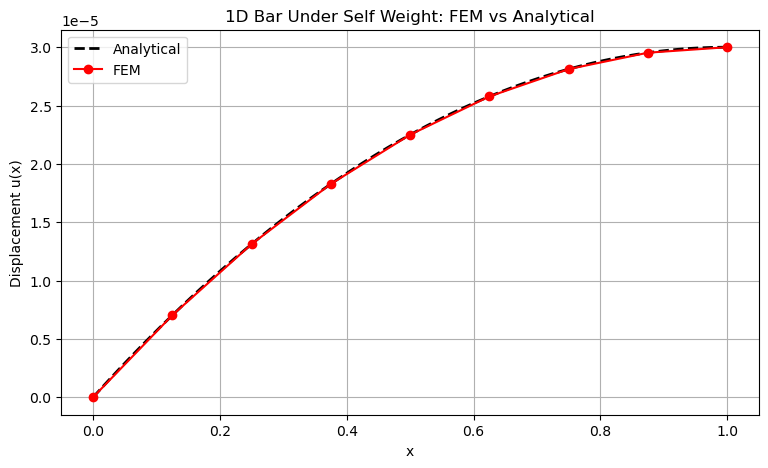

In [6]:
# ------------------------------------------------------
# ANALYTICAL SOLUTION
# ------------------------------------------------------
def u_exact(x):
    return (rho*g/E) * (L*x - 0.5*x**2)

x_exact = np.linspace(0, L, 300)
u_exact_vals = u_exact(x_exact)

x_fem = Coord[:, 0]
u_fem = U[:, 0]

# ------------------------------------------------------
# PLOT FEM vs EXACT DISPLACEMENT
# ------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(x_exact, u_exact_vals, 'k--', linewidth=2, label="Analytical")
plt.plot(x_fem, u_fem, 'ro-', label="FEM", markersize=6)
plt.xlabel("x")
plt.ylabel("Displacement u(x)")
plt.title("1D Bar Under Self Weight: FEM vs Analytical")
plt.grid(True)
plt.legend()
plt.savefig("1D Bar Under Self Weight.pdf")
#plt.tight_layout()
plt.show()


Running mesh with 5 elements...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (6, 1),   NEqns = 5

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (1, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (5, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (6, 1)

Linear elasticity simulation completed successfully.


Running mesh with 10 elements...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (11, 1),   NEqns = 10

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (1, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F s

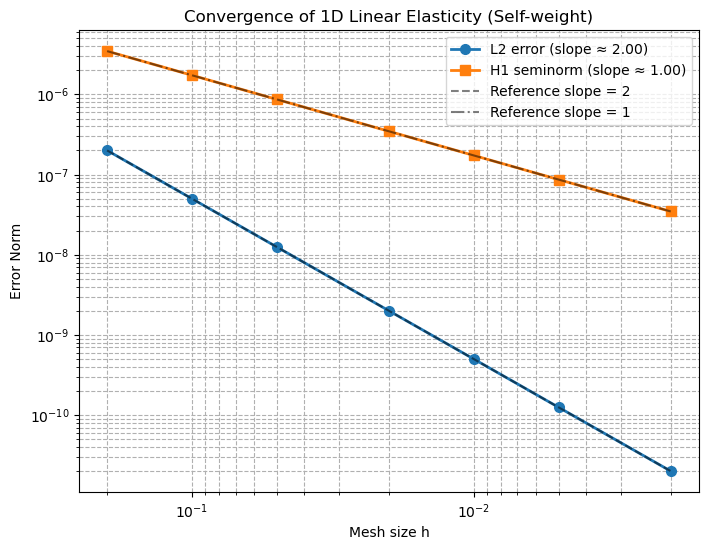

In [7]:
# ----------------------------------------------------------
#  Exact solution and derivative
# ----------------------------------------------------------
def get_exact_solution(x_vec):
    x = x_vec[0]
    u = (rhob / E) * (L*x - 0.5*x**2)
    du = np.array([(rhob / E) * (L - x)])
    return u, du

# ----------------------------------------------------------
#  Mesh refinements
# ----------------------------------------------------------
mesh_list = [5, 10, 20, 50, 100, 200, 500]
err_L2 = []
err_H1 = []
hs = []

for Nele in mesh_list:
    print(f"\nRunning mesh with {Nele} elements...")
    NumNodes = Nele + 1
    NCons = 1

    # Coordinates
    Coord = np.zeros((NumNodes,1))
    Coord[:,0] = np.linspace(0,L,NumNodes)

    # Connectivity (1-based for Calculate_Error)
    Connectivity = np.zeros((Nele, 2), dtype=int)
    for e in range(Nele):
        Connectivity[e,:] = [e+1, e+2]

    # Boundary condition u(0)=0
    Constraints = np.array([[1, 1, 0.0]])

    # No point loads
    ptloads = np.zeros((0,3))

    # FEM solve
    U = Driver_LE(
        Connectivity, Constraints, Coord,
        medium_set, dim, dofs_per_node,
        EleType, load_type, NCons, Nele,
        NGPTS, NumNodes, ptloads
    )

    # Compute L2 and H1 errors
    L2, H1 = Calculate_Error(
        Connectivity, Coord, EleType, NGPTS,
        U, get_exact_solution, verbose=False
    )

    err_L2.append(L2)
    err_H1.append(H1)
    hs.append(L / Nele)

# ----------------------------------------------------------
#  Convergence table
# ----------------------------------------------------------
print("\n====================================================")
print(" Convergence Results (L2 and H1 Errors)")
print("====================================================")
print("  Nele      h          L2 Error       H1 Error")
for Nele, h, eL2, eH1 in zip(mesh_list, hs, err_L2, err_H1):
    print(f"{Nele:6d}   {h:10.6f}   {eL2:12.6e}   {eH1:12.6e}")

# ----------------------------------------------------------
#  Compute convergence slopes (order of accuracy)
# ----------------------------------------------------------
# Fit log(error) = a + p*log(h) → p = slope
slope_L2 = np.polyfit(np.log(hs), np.log(err_L2), 1)[0]
slope_H1 = np.polyfit(np.log(hs), np.log(err_H1), 1)[0]

print("\n====================================================")
print(" Convergence Slopes")
print("====================================================")
print(f"  L2  error slope  = {abs(slope_L2):.4f}")
print(f"  H1  error slope  = {abs(slope_H1):.4f}")

# ----------------------------------------------------------
#  Convergence Plot with Slopes
# ----------------------------------------------------------
plt.figure(figsize=(8,6))

# Actual FEM errors
plt.loglog(hs, err_L2, 'o-', linewidth=2, markersize=7, label=f"L2 error (slope ≈ {abs(slope_L2):.2f})")
plt.loglog(hs, err_H1, 's-', linewidth=2, markersize=7, label=f"H1 seminorm (slope ≈ {abs(slope_H1):.2f})")

# Reference lines (slope = 2 and slope = 1)
h_ref = np.array(hs)
ref_L2 = err_L2[0] * (h_ref / h_ref[0])**2     # h^2 line
ref_H1 = err_H1[0] * (h_ref / h_ref[0])**1     # h^1 line

plt.loglog(h_ref, ref_L2, 'k--', alpha=0.5, label="Reference slope = 2")
plt.loglog(h_ref, ref_H1, 'k-.', alpha=0.5, label="Reference slope = 1")

plt.gca().invert_xaxis()
plt.xlabel("Mesh size h")
plt.ylabel("Error Norm")
plt.title("Convergence of 1D Linear Elasticity (Self-weight)")
plt.grid(True, which="both", ls="--")
plt.legend()

plt.savefig("Problem1_4_Convergence_with_slopes.pdf")
print("\nSaved convergence plot as Problem1_4_Convergence_with_slopes.pdf")

plt.show()



 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (9, 1),   NEqns = 8

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (1, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (8, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (9, 1)

Linear elasticity simulation completed successfully.


Saved stress comparison figure as Problem1_5_Stress_Comparison.pdf


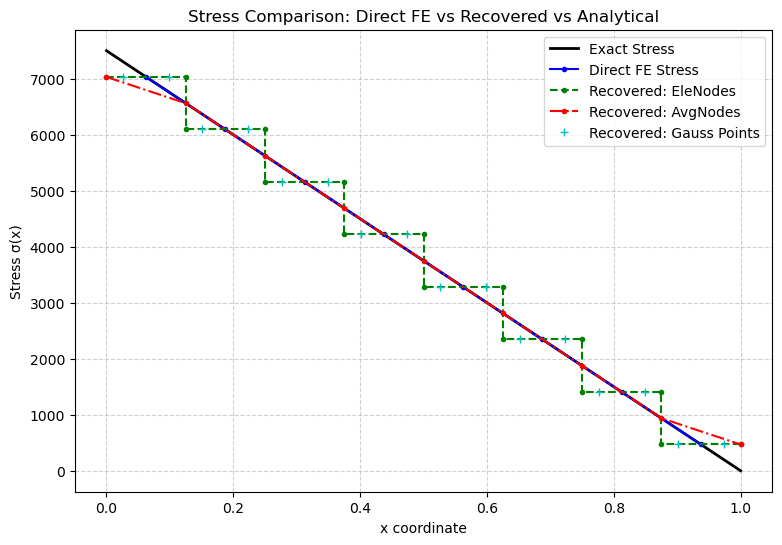

In [8]:
# ======================================================================
#  Problem 1.5 – Stress Comparison (Direct FE vs Recovered vs Analytical)
#  Author: Nafeezat Ajenifuja (with ChatGPT assistant)
# ======================================================================
# ----------------------------------------------------------
#  Physical + material parameters
# ----------------------------------------------------------
L = 1.0
rho = 1500.0
g = 10.0
A = 0.5                   # cross section area
rhob = rho * g * A

E = 250e6
nu = 0

lambda_ = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_     = E / (2 * (1 + nu))
E_eff   = lambda_ + 2 * mu_     # effective modulus used by your LE kernel

medium_set = {
    "type": "Lame_params",
    "lambda": lambda_,
    "mu": mu_
}

load_type = {
    "case": "1D_gravity",
    "rhob": rhob
}

dim = 1
dofs_per_node = 1
EleType = "L2"
NGPTS = 2

# ----------------------------------------------------------
#  Build a reasonably fine mesh for smooth stress plotting
# ----------------------------------------------------------
Nele = 8
NumNodes = Nele + 1
NCons = 1

Coord = np.zeros((NumNodes, 1))
Coord[:, 0] = np.linspace(0, L, NumNodes)

Connectivity = np.zeros((Nele, 2), dtype=int)
for e in range(Nele):
    Connectivity[e, :] = [e+1, e+2]

Constraints = np.array([[1, 1, 0.0]])
ptloads = np.zeros((0, 3))      # no point loads

# ----------------------------------------------------------
#  Solve FEM displacement
# ----------------------------------------------------------
U = Driver_LE(
    Connectivity, Constraints, Coord,
    medium_set, dim, dofs_per_node,
    EleType, load_type, NCons, Nele,
    NGPTS, NumNodes, ptloads
)

# ----------------------------------------------------------
#  1. Analytical Stress:  sigma_exact(x) = rho_g (L − x)
# ----------------------------------------------------------
x_exact = Coord[:,0]
sigma_exact = rhob * (L - x_exact)   # divide by A because rhob = rho*g*A

# ----------------------------------------------------------
#  2. Direct FEM Stress: sigma = E * du/dx on each element
# ----------------------------------------------------------
sigma_direct = np.zeros(Nele)

for e in range(Nele):
    i, j = e, e+1
    dx = Coord[j,0] - Coord[i,0]
    du = U[j,0] - U[i,0]
    strain = du / dx
    sigma_direct[e] = E * strain

x_direct = 0.5 * (Coord[:-1,0] + Coord[1:,0])   # element centers

# ----------------------------------------------------------
#  3. Stress Recovery Methods from your code
# ----------------------------------------------------------
# Gauss Points (GPT)
sigma_GPT = Stress_Recovery(
    Connectivity, Coord, EleType,
    medium_set, NGPTS, "GPT", U
)

# Element Nodes (EleNodes)
sigma_EleNodes = Stress_Recovery(
    Connectivity, Coord, EleType,
    medium_set, NGPTS, "EleNodes", U
)

# Averaged Nodes (AvgNodes)
sigma_AvgNodes = Stress_Recovery(
    Connectivity, Coord, EleType,
    medium_set, NGPTS, "AvgNodes", U
)

# ----------------------------------------------------------
#  PLOTTING
# ----------------------------------------------------------
plt.figure(figsize=(9,6))

# Analytical
plt.plot(x_exact, sigma_exact, 'k-', linewidth=2, label="Exact Stress")

# Direct FE (piecewise)
plt.plot(x_direct, sigma_direct, 'bo-', markersize=3, label="Direct FE Stress")

# Recovered stresses
plt.plot(sigma_EleNodes[:,0], sigma_EleNodes[:,1], 'g.--', label="Recovered: EleNodes")
plt.plot(sigma_AvgNodes[:,0], sigma_AvgNodes[:,1], 'r.-.', label="Recovered: AvgNodes")
plt.plot(sigma_GPT[:,0], sigma_GPT[:,1], 'c+', label="Recovered: Gauss Points")

plt.xlabel("x coordinate")
plt.ylabel("Stress σ(x)")
plt.title("Stress Comparison: Direct FE vs Recovered vs Analytical")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.savefig("Problem1_5_Stress_Comparison_coarse.pdf", format="pdf")
print("\nSaved stress comparison figure as Problem1_5_Stress_Comparison.pdf")

plt.show()


### 2. Bending of a Cantilever Beam

In [9]:
def generate_Q8_cantilever_mesh(L=1.0, H=0.1, Nele_x=4,
                                E=200e6, nu=0.3,
                                rho=1000.0, g=10.0):
    """
    Correct Q8 mesh generator.
    - Exactly 1 element through thickness
    - Q8 ordering matches Shape_Q8:
    
        Node order (counter-clockwise):
            1 bottom-left
            2 bottom-mid
            3 bottom-right
            4 right-mid
            5 top-right
            6 top-mid
            7 top-left
            8 left-mid
    """

    # -------------------------------------------
    # 1) NODE GRID (NO SKIPPING, ALL NODES VALID)
    # -------------------------------------------
    Nx = 2 * Nele_x + 1     # 0..2N
    Ny = 3                  # bottom, mid, top

    x_vals = np.linspace(0, L, Nx)
    y_vals = np.array([-H/2, 0.0, H/2])

    Coord = np.zeros((Nx * Ny, 2))

    def nid(i, j):
        return j * Nx + i

    idx = 0
    for j in range(Ny):
        for i in range(Nx):
            Coord[idx, :] = [x_vals[i], y_vals[j]]
            idx += 1

    # -------------------------------------------
    # 2) CORRECT Q8 CONNECTIVITY
    # -------------------------------------------
    Connectivity = np.zeros((Nele_x, 8), dtype=int)

    for e in range(Nele_x):
        iL = 2 * e
        iM = 2 * e + 1
        iR = 2 * e + 2

        # CORNERS
        n1 = nid(iL, 0)
        n3 = nid(iR, 0)
        n5 = nid(iR, 2)
        n7 = nid(iL, 2)

        # MIDSIDES
        n2 = nid(iM, 0)
        n4 = nid(iR, 1)
        n6 = nid(iM, 2)
        n8 = nid(iL, 1)

        # MUST MATCH Shape_Q8 EXACT ordering
        Connectivity[e, :] = np.array([
            n1 + 1,  # BL
            n3 + 1,  # BR
            n5 + 1,  # TR
            n7 + 1,  # TL
            n2 + 1,  # Bmid
            n4 + 1,  # Rmid
            n6 + 1,  # Tmid
            n8 + 1   # Lmid
        ])

    # -------------------------------------------
    # 3) DIRICHLET BC (CLAMPED END)
    # -------------------------------------------
    left_nodes = np.where(np.isclose(Coord[:, 0], 0.0))[0]

    Constraints = []
    for n in left_nodes:
        Constraints.append([n+1, 1, 0.0])  # Ux = 0
        Constraints.append([n+1, 2, 0.0])  # Uy = 0

    Constraints = np.array(Constraints, float)

    # -------------------------------------------
    # 3b. OPTIONAL SAFETY: constrain unused nodes
    # -------------------------------------------
    NumNodes = Coord.shape[0]

    # nodes that actually appear in any element (0-based)
    used_nodes = np.unique(Connectivity) - 1
    all_nodes = np.arange(NumNodes)

    # nodes that are not used in Connectivity at all
    unused_nodes = np.setdiff1d(all_nodes, used_nodes)

    if unused_nodes.size > 0:
        extra_constraints = []
        for n in unused_nodes:
            # Constrain both DOFs of these orphan nodes
            extra_constraints.append([n + 1, 1, 0.0])  # Ux = 0
            extra_constraints.append([n + 1, 2, 0.0])  # Uy = 0

        if Constraints.size == 0:
            Constraints = np.array(extra_constraints, dtype=float)
        else:
            Constraints = np.vstack([Constraints,
                                     np.array(extra_constraints, dtype=float)])


    # -------------------------------------------
    # 4) MATERIAL (Lamé)
    # -------------------------------------------
    lam = E * nu / ((1 + nu)*(1 - 2*nu))
    mu  = E / (2*(1 + nu))

    medium_set = {
        "type": "Lame_params",
        "lambda": lam,
        "mu": mu
    }

    # -------------------------------------------
    # 5) BODY FORCE (your convention is correct)
    # -------------------------------------------
    load_type = {
        "case": "2D_gravity",
        "rhob": rho * g
    }

    return Coord, Connectivity, Constraints, medium_set, load_type


In [10]:
# ================================================================
#  PROBLEM 2.2 — Solve Cantilever Beam Bending with Q8 Elements
# ================================================================

# -------------------------------
# 1. Generate Q8 Mesh (Problem 2.1)
# -------------------------------
Nele_x = 4     # number of Q8 elements along length (you can refine later)
L = 1.0        # beam length
H = 0.1        # beam depth

Coord, Connectivity, Constraints, medium_set, load_type = \
    generate_Q8_cantilever_mesh(L=L, H=H, Nele_x=Nele_x)

NumNodes = Coord.shape[0]
Nele = Connectivity.shape[0]
NCons = Constraints.shape[0]

print("==============================================")
print(" Q8 Cantilever Mesh Successfully Generated")
print("==============================================")
print(f"  Number of elements     : {Nele}")
print(f"  Number of nodes        : {NumNodes}")
print(f"  Number of constraints  : {NCons}")
print("----------------------------------------------\n")


# -------------------------------
# 2. FEM Simulation Parameters
# -------------------------------
dim = 2               # 2D elasticity
dofs_per_node = 2     # ux, uy
EleType = "Q8"        # 8-node quadrilateral
NGPTS = 3             # 3×3 Gauss rule for Q8
ptload = None         # no point load, using body force gravity


# -------------------------------
# 3. Solve using Driver_LE
# -------------------------------
print("==============================================")
print(" Solving Linear Elasticity Problem (Q8) ...")
print("==============================================")

U = Driver_LE(Connectivity, Constraints, Coord,
              medium_set, dim, dofs_per_node,
              EleType, load_type,
              NCons, Nele, NGPTS, NumNodes,
              ptload)

print("==============================================")
print(" FEM Simulation Completed")
print("==============================================\n")


# -------------------------------
# 4. Extract tip displacement
# -------------------------------
# Tip = node(s) where x = L
tip_nodes = np.where(np.isclose(Coord[:,0], L))[0]
tip_uy = U[tip_nodes, 1]   # vertical displacement

print("----------------------------------------------")
print(" TIP DISPLACEMENT RESULTS")
print("----------------------------------------------")
for i, n in enumerate(tip_nodes):
    print(f"   Node {n+1:4d} : uy = {tip_uy[i]: .6e} m")
print("----------------------------------------------\n")

# -------------------------------
# 5. Optional: Compute average tip displacement
# -------------------------------
uy_avg = np.mean(tip_uy)
print(f" Average tip deflection: {uy_avg:.6e} m\n")

 Q8 Cantilever Mesh Successfully Generated
  Number of elements     : 4
  Number of nodes        : 27
  Number of constraints  : 14
----------------------------------------------

 Solving Linear Elasticity Problem (Q8) ...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (27, 2),   NEqns = 40

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (14, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (40, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (27, 2)

Linear elasticity simulation completed successfully.

 FEM Simulation Completed

----------------------------------------------
 TIP DISPLACEMENT RESULTS
----------------------------------------------
   Node    9 : uy = -6.497942e-03 m
   Node   18 : uy = -6.498161e-03 m
   Node   27 : uy = -6.497942e-03 m
----------------------------------------------




Running Q8 mesh with 2 elements along x...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (15, 2),   NEqns = 20

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (10, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (20, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (15, 2)

Linear elasticity simulation completed successfully.

  → Tip displacement = -7.011331e-03

Running Q8 mesh with 4 elements along x...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (27, 2),   NEqns = 40

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (14, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (40, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U

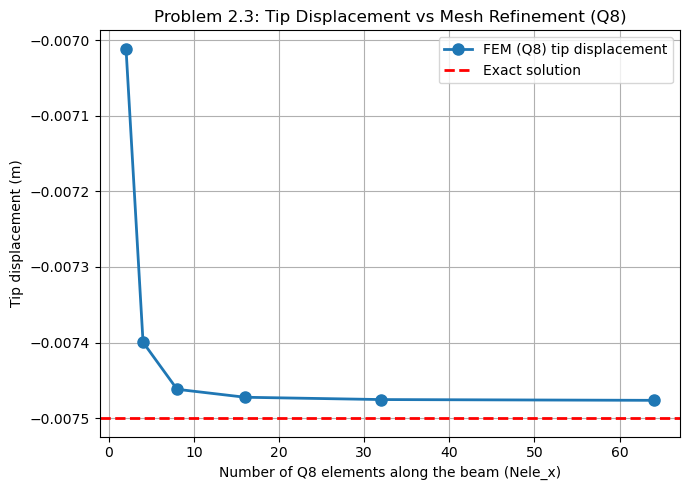


Plot saved as "Problem2_3_TipDisp_vs_Mesh.pdf"


In [11]:
# =================================================
#  Physical parameters
# =================================================
L = 1.0
H = 0.1
E = 200e6
nu = 0.1
rho = 1000.0
g = 10.0

# Distributed load from self-weight
q0 = rho * g * H

# Second moment of area for unit width
I = (H**3) / 12.0

# Exact Euler–Bernoulli tip displacement
u_exact = -q0 * L**4 / (8 * E * I)


# =================================================
#  Mesh refinements to test
# =================================================
Nele_x_list = [2, 4, 8, 16, 32, 64]

u_FE_list = []   # store FE tip displacements


# =================================================
#  Compute FE solution for each mesh
# =================================================
for Nele_x in Nele_x_list:

    print(f"\nRunning Q8 mesh with {Nele_x} elements along x...")

    # Generate mesh and FEM inputs
    Coord, Connectivity, Constraints, medium_set, load_type = \
        generate_Q8_cantilever_mesh(
            L=L, H=H,
            Nele_x=Nele_x,
            E=E, nu=nu,
            rho=rho, g=g
        )

    NumNodes = Coord.shape[0]
    Nele = Connectivity.shape[0]
    NCons = Constraints.shape[0]

    dim = 2
    dofs_per_node = 2
    EleType = "Q8"
    NGPTS = 3
    ptload = None

    # Solve elasticity problem
    U = Driver_LE(
        Connectivity, Constraints, Coord,
        medium_set, dim, dofs_per_node,
        EleType, load_type,
        NCons, Nele, NGPTS, NumNodes,
        ptload
    )

    # Extract tip displacement at neutral axis (y = 0)
    tip_nodes = np.where(
        (np.isclose(Coord[:, 0], L)) &
        (np.isclose(Coord[:, 1], 0.0))
    )[0]

    tip_node = tip_nodes[0]
    uy_tip = U[tip_node, 1]

    u_FE_list.append(uy_tip)

    print(f"  → Tip displacement = {uy_tip:.6e}")


# =================================================
#  Plot tip displacement vs number of elements
# =================================================
plt.figure(figsize=(7, 5))

plt.plot(Nele_x_list, u_FE_list, 'o-', linewidth=2, markersize=8,
         label="FEM (Q8) tip displacement")

# Plot the exact displacement as horizontal line
plt.axhline(u_exact, color='r', linestyle='--', linewidth=2,
            label="Exact solution")

plt.xlabel("Number of Q8 elements along the beam (Nele_x)")
plt.ylabel("Tip displacement (m)")
plt.title("Problem 2.3: Tip Displacement vs Mesh Refinement (Q8)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("Problem2_3_TipDisp_vs_Mesh.pdf")
plt.show()

print('\nPlot saved as "Problem2_3_TipDisp_vs_Mesh.pdf"')

In [12]:
def generate_Q4_cantilever_mesh(L=1.0, H=0.1, Nele_x=4, Nele_y=1,
                                E=200e6, nu=0.3,
                                rho=1000.0, g=10.0):
    """
    Q4 cantilever mesh (structured).
    Node ordering matches your Shape_Q4 (standard bilinear).
    """

    # -------------------------------------------
    # 1) GRID
    # -------------------------------------------
    Nx = Nele_x + 1
    Ny = Nele_y + 1

    x_vals = np.linspace(0, L, Nx)
    y_vals = np.linspace(-H/2, H/2, Ny)

    Coord = np.zeros((Nx * Ny, 2))
    
    def nid(i, j):
        return j * Nx + i

    idx = 0
    for j in range(Ny):
        for i in range(Nx):
            Coord[idx, :] = [x_vals[i], y_vals[j]]
            idx += 1

    # -------------------------------------------
    # 2) CONNECTIVITY (Q4: 4 nodes/element)
    # -------------------------------------------
    Connectivity = np.zeros((Nele_x * Nele_y, 4), dtype=int)

    e = 0
    for j in range(Nele_y):
        for i in range(Nele_x):
            n1 = nid(i, j)
            n2 = nid(i+1, j)
            n3 = nid(i+1, j+1)
            n4 = nid(i, j+1)

            Connectivity[e, :] = np.array([n1+1, n2+1, n3+1, n4+1])
            e += 1

    # -------------------------------------------
    # 3) DIRICHLET CONDITIONS (clamped at x=0)
    # -------------------------------------------
    left_nodes = np.where(np.isclose(Coord[:, 0], 0.0))[0]

    Constraints = []
    for n in left_nodes:
        Constraints.append([n+1, 1, 0.0])  # Ux = 0
        Constraints.append([n+1, 2, 0.0])  # Uy = 0

    Constraints = np.array(Constraints, float)

    # -------------------------------------------
    # 4) MATERIAL
    # -------------------------------------------
    lam = E * nu / ((1 + nu)*(1 - 2*nu))
    mu  = E / (2*(1 + nu))

    medium_set = {
        "type": "Lame_params",
        "lambda": lam,
        "mu": mu
    }

    # -------------------------------------------
    # 5) BODY FORCE (same as Q8 for comparability)
    # -------------------------------------------
    load_type = {
        "case": "2D_gravity",
        "rhob": rho * g
    }

    return Coord, Connectivity, Constraints, medium_set, load_type


In [13]:
Nele_x_list = [2, 4, 8, 16, 32, 64]

u_Q4_1   = []
u_Q4_4   = []
u_Q8_1   = []

for Nele_x in Nele_x_list:

    # ===========================
    # Q4 — 1 layer (locking)
    # ===========================
    Coord, Conn, Cons, mat, load = generate_Q4_cantilever_mesh(
        L=L, H=H,
        Nele_x=Nele_x, Nele_y=1,
        E=E, nu=0.3, rho=rho, g=g
    )

    U = Driver_LE(Conn, Cons, Coord, mat, 2, 2,
                  "Q4", load,
                  Cons.shape[0], Conn.shape[0], 2, Coord.shape[0], None)

    tip_nodes = np.where(np.isclose(Coord[:,0], L))[0]

    # among these nodes, pick the one closest to y = 0
    yvals = Coord[tip_nodes, 1]
    mid_idx = np.argmin(np.abs(yvals - 0.0))
    tip_node = tip_nodes[mid_idx]

    u_Q4_1.append(U[tip_node, 1])

    # ===========================
    # Q4 — 4 layers (less locking)
    # ===========================
    Coord, Conn, Cons, mat, load = generate_Q4_cantilever_mesh(
        L=L, H=H,
        Nele_x=Nele_x, Nele_y=4,
        E=E, nu=nu, rho=rho, g=g
    )

    U = Driver_LE(Conn, Cons, Coord, mat, 2, 2,
                  "Q4", load,
                  Cons.shape[0], Conn.shape[0], 2, Coord.shape[0], None)

    tip_node = np.where((np.isclose(Coord[:,0], L)) &
                        (np.isclose(Coord[:,1], 0.0)))[0][0]

    # tip_nodes = np.where(np.isclose(Coord[:,0], L))[0]

    # # among these nodes, pick the one closest to y = 0
    # yvals = Coord[tip_nodes, 1]
    # mid_idx = np.argmin(np.abs(yvals - 0.0))
    # tip_node = tip_nodes[mid_idx]

    u_Q4_4.append(U[tip_node, 1])

    # ===========================
    # Q8 — 1 layer (best)
    # ===========================
    Coord, Conn, Cons, mat, load = generate_Q8_cantilever_mesh(
        L=L, H=H,
        Nele_x=Nele_x,
        E=E, nu=nu, rho=rho, g=g
    )

    U = Driver_LE(Conn, Cons, Coord, mat, 2, 2,
                  "Q8", load,
                  Cons.shape[0], Conn.shape[0], 3, Coord.shape[0], None)

    tip_node = np.where((np.isclose(Coord[:,0], L)) &
                        (np.isclose(Coord[:,1], 0.0)))[0][0]

    u_Q8_1.append(U[tip_node, 1])



 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (6, 2),   NEqns = 8

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (4, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (8, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (6, 2)

Linear elasticity simulation completed successfully.


 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (15, 2),   NEqns = 20

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (10, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (20, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (15, 2)

Linear elasticity simulation completed successfully.


 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creat

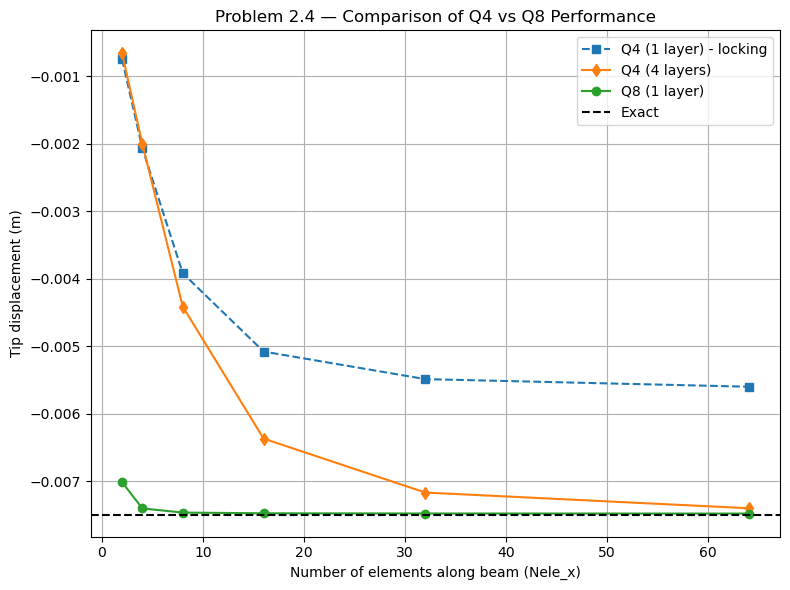

In [14]:
plt.figure(figsize=(8,6))

plt.plot(Nele_x_list, u_Q4_1, 's--', label="Q4 (1 layer) - locking")
plt.plot(Nele_x_list, u_Q4_4, 'd-', label="Q4 (4 layers)")
plt.plot(Nele_x_list, u_Q8_1, 'o-', label="Q8 (1 layer)")
plt.axhline(u_exact, color='k', linestyle='--', label="Exact")

plt.xlabel("Number of elements along beam (Nele_x)")
plt.ylabel("Tip displacement (m)")
plt.title("Problem 2.4 — Comparison of Q4 vs Q8 Performance")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Problem2_4_Q4_vs_Q8.pdf")
plt.show()


### 3. Thick Cylinder (Modifed Lame Problem)

Running Modified Lame Problem (clean version)...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (360, 2),   NEqns = 560

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (160, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (560, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (360, 2)

Linear elasticity simulation completed successfully.



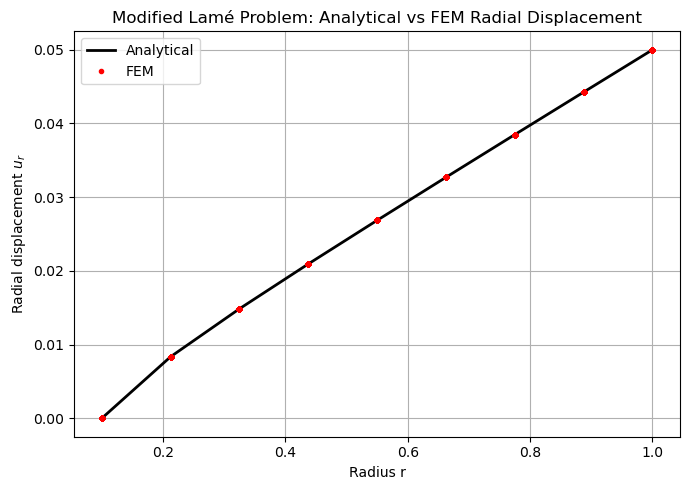

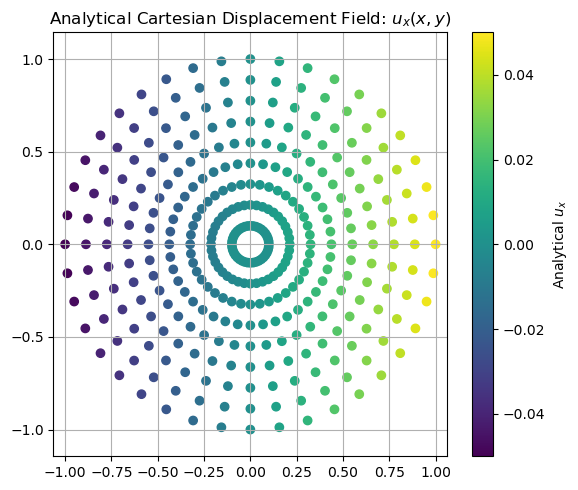

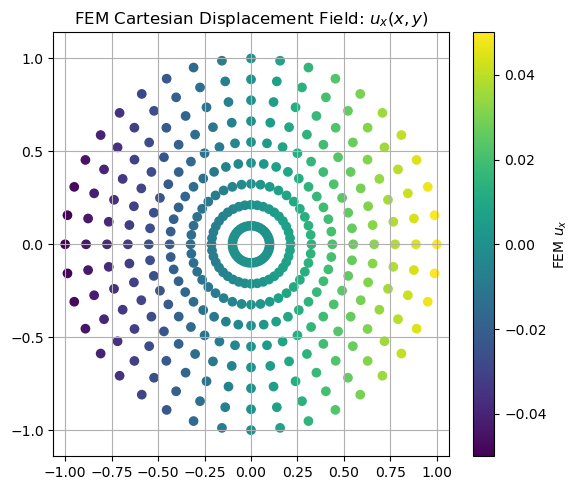

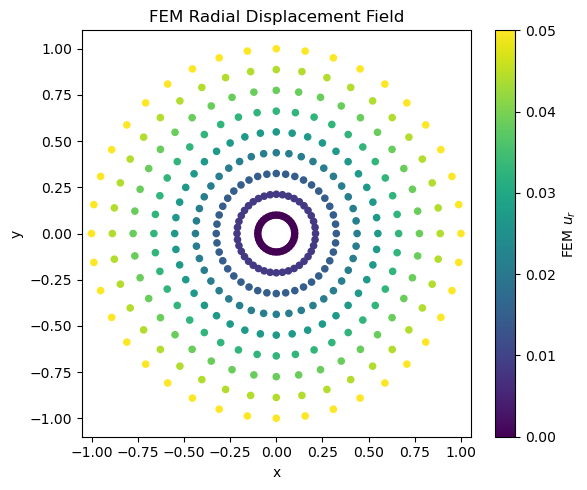

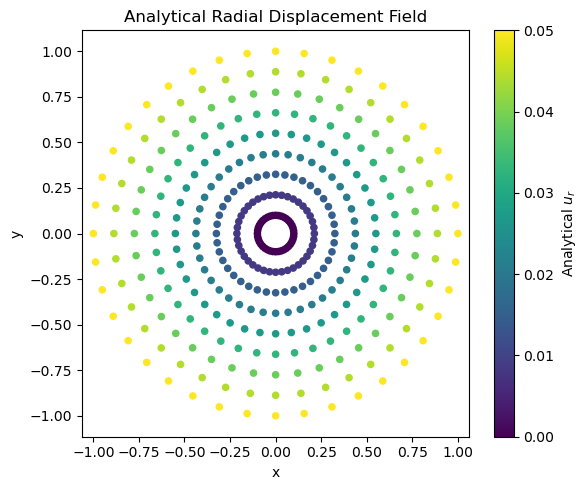

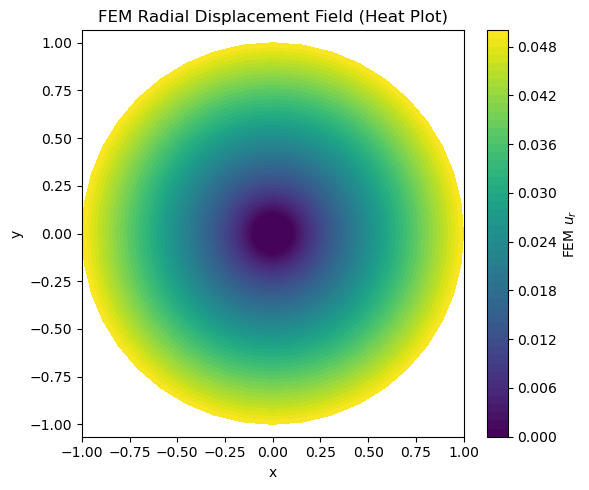

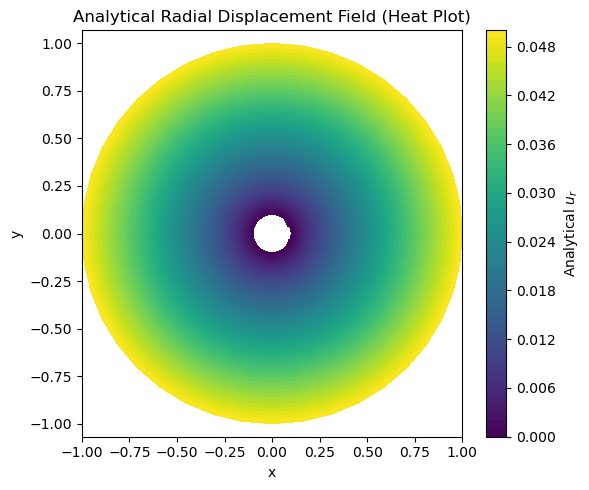

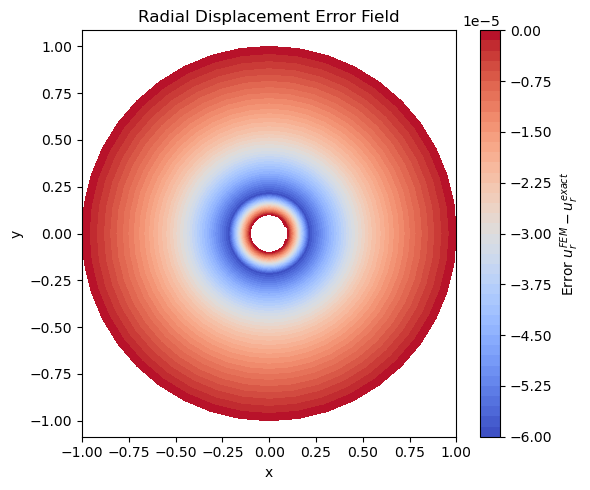

In [15]:
# ============================================================
# Analytical radial displacement from Problem 3.2
# ============================================================
def u_r_exact(r, ri, ro, u0):
    return (u0 * ro / (ro**2 - ri**2)) * (r - (ri**2)/r)


# ============================================================
# Mesh generator: Q4 full annulus in Cartesian coordinates
# ============================================================
def generate_full_cylinder_Q4_mesh(ri, ro, Nr, Ntheta, E, nu, u0):

    r_vals = np.linspace(ri, ro, Nr + 1)
    theta_vals = np.linspace(0, 2*np.pi, Ntheta + 1)[:-1]

    NumNodes = (Nr + 1) * Ntheta
    Coord = np.zeros((NumNodes, 2))

    def nid(i, j):
        return j * (Nr + 1) + i

    # Node coordinates
    for j, theta in enumerate(theta_vals):
        c, s = np.cos(theta), np.sin(theta)
        for i, r in enumerate(r_vals):
            idx = nid(i, j)
            Coord[idx] = [r*c, r*s]

    # Connectivity
    Nele = Nr * Ntheta
    Connectivity = np.zeros((Nele, 4), dtype=int)

    e = 0
    for j in range(Ntheta):
        jp = (j + 1) % Ntheta
        for i in range(Nr):
            Connectivity[e] = [
                nid(i, j) + 1,
                nid(i+1, j) + 1,
                nid(i+1, jp) + 1,
                nid(i, jp) + 1
            ]
            e += 1

    # Boundary conditions
    Constraints = []

    # Inner radius fixed
    for j in range(Ntheta):
        n = nid(0, j)
        Constraints.append([n+1, 1, 0.0])
        Constraints.append([n+1, 2, 0.0])

    # Outer radius displacement u_r = u0
    for j in range(Ntheta):
        n = nid(Nr, j)
        x, y = Coord[n]
        r = np.sqrt(x*x + y*y)
        ex, ey = x/r, y/r
        Constraints.append([n+1, 1, u0*ex])
        Constraints.append([n+1, 2, u0*ey])

    Constraints = np.array(Constraints, float)

    # Material (plane stress)
    lam = E*nu / (1 - nu**2)
    mu  = E / (2*(1 + nu))
    medium_set = {"type": "Lame_params", "lambda": lam, "mu": mu}

    # IMPORTANT: your Get_Rhob does not support "none", so use 0 gravity
    load_type = {"case": "2D_gravity", "rhob": 0.0}

    return Coord, Connectivity, Constraints, medium_set, load_type


# ============================================================
# Run Problem 3.3 with ONLY the overlay plot
# ============================================================
def run_thick_cylinder_example():

    # Problem data
    ri = 0.1
    ro = 1.0
    u0 = 0.05
    E  = 100000.0
    nu = 0.3

    Nr = 8
    Ntheta = 40

    Coord, Conn, Cons, mat, load = generate_full_cylinder_Q4_mesh(
        ri, ro, Nr, Ntheta, E, nu, u0
    )

    NumNodes = Coord.shape[0]
    Nele     = Conn.shape[0]
    NCons    = Cons.shape[0]

    print("Running Modified Lame Problem (clean version)...")

    # Solve FEM
    U = Driver_LE(
        Conn, Cons, Coord,
        mat, 2, 2,
        "Q4", load,
        NCons, Nele, 2, NumNodes,
        None
    )

    # Compute radial displacement
    x, y = Coord[:,0], Coord[:,1]
    r = np.sqrt(x*x + y*y)

    ex, ey = x/r, y/r
    ux, uy = U[:,0], U[:,1]

    u_r_fem = ux*ex + uy*ey
    u_r_an  = u_r_exact(r, ri, ro, u0)

    # Sort by r for smooth plot
    idx = np.argsort(r)
    r_sorted      = r[idx]
    u_r_fem_sorted = u_r_fem[idx]
    u_r_an_sorted  = u_r_an[idx]

    # --------------------------------------------------------
    # Clean overlay plot: FEM vs Analytical
    # --------------------------------------------------------
    plt.figure(figsize=(7,5))
    plt.plot(r_sorted, u_r_an_sorted, 'k-', linewidth=2, label="Analytical")
    plt.plot(r_sorted, u_r_fem_sorted, 'ro', markersize=3, label="FEM")
    plt.xlabel("Radius r")
    plt.ylabel("Radial displacement $u_r$")
    plt.title("Modified Lamé Problem: Analytical vs FEM Radial Displacement")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig("Modified Lame Problem.pdf")
    plt.show()

    # analytical radial displacement
    u_r_an = u_r_exact(r, ri, ro, u0)
    
    # analytical Cartesian components
    u_x_an = u_r_an * ex
    u_y_an = u_r_an * ey
    
    
    # ==============================================================
    #  1) Scatter comparison: FEM vs Analytical
    # ==============================================================
    
    plt.figure(figsize=(6,5))
    plt.scatter(Coord[:,0], Coord[:,1], c=u_x_an, cmap='viridis')
    plt.colorbar(label="Analytical $u_x$")
    plt.title("Analytical Cartesian Displacement Field: $u_x(x,y)$")
    plt.axis("equal")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("Analytical Cartesian Displacement Field.pdf")
    plt.show()
    
    plt.figure(figsize=(6,5))
    plt.scatter(Coord[:,0], Coord[:,1], c=U[:,0], cmap='viridis')
    plt.colorbar(label="FEM $u_x$")
    plt.title("FEM Cartesian Displacement Field: $u_x(x,y)$")
    plt.axis("equal")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("FEM Cartesian Displacement Field.pdf")
    plt.show()

    # Compute radial displacement at ALL nodes
    x = Coord[:, 0]
    y = Coord[:, 1]
    r = np.sqrt(x**2 + y**2)
    
    ux = U[:, 0]
    uy = U[:, 1]
    
    u_r_fem = ux * (x / r) + uy * (y / r)
    
    # Plot full-field FEM radial displacement
    plt.figure(figsize=(6, 5))
    plt.scatter(x, y, c=u_r_fem, cmap='viridis', s=20)
    plt.colorbar(label="FEM $u_r$")
    plt.axis('equal')
    plt.title("FEM Radial Displacement Field")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.tight_layout()
    plt.savefig("FEM Radial Displacement Field.pdf")
    plt.show()

    # ==============================================================
    #  Analytical radial displacement field plot (full-field)
    # ==============================================================
    plt.figure(figsize=(6, 5))
    plt.scatter(x, y, c=u_r_an, cmap='viridis', s=20)
    plt.colorbar(label="Analytical $u_r$")
    plt.axis('equal')
    plt.title("Analytical Radial Displacement Field")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.tight_layout()
    plt.savefig("Analytical Radial Displacement Field.pdf")
    plt.show()

    # Triangulate the node coordinates
    triang = tri.Triangulation(x, y)
    
    # ============================================================
    # Heat plot (filled contour) of FEM radial displacement
    # ============================================================
    plt.figure(figsize=(6,5))
    plt.tricontourf(triang, u_r_fem, levels=50, cmap='viridis')
    plt.colorbar(label="FEM $u_r$")
    plt.title("FEM Radial Displacement Field (Heat Plot)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis('equal')
    plt.tight_layout()
    plt.savefig("FEM_Radial_HeatPlot.pdf")
    plt.show()
    
    # ============================================================
    # Heat plot (filled contour) of Analytical radial displacement
    # ============================================================
    plt.figure(figsize=(6,5))
    plt.tricontourf(triang, u_r_an, levels=50, cmap='viridis')
    plt.colorbar(label="Analytical $u_r$")
    plt.title("Analytical Radial Displacement Field (Heat Plot)")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis('equal')
    plt.tight_layout()
    plt.savefig("Analytical_Radial_HeatPlot.pdf")
    plt.show()

    u_r_err = u_r_fem - u_r_an

    plt.figure(figsize=(6,5))
    plt.tricontourf(triang, u_r_err, levels=50, cmap='coolwarm')
    plt.colorbar(label="Error $u_r^{FEM} - u_r^{exact}$")
    plt.title("Radial Displacement Error Field")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis('equal')
    plt.tight_layout()
    plt.savefig("Radial_Error_Field.pdf")
    plt.show()

if __name__ == "__main__":
    run_thick_cylinder_example()



=== Mesh Nr=4, Ntheta=16, h=0.2250 ===

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (80, 2),   NEqns = 96

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (64, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (96, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (80, 2)

Linear elasticity simulation completed successfully.

Strain energy = 1112.077436

=== Mesh Nr=8, Ntheta=32, h=0.1125 ===

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (288, 2),   NEqns = 448

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (128, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (448, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (288,

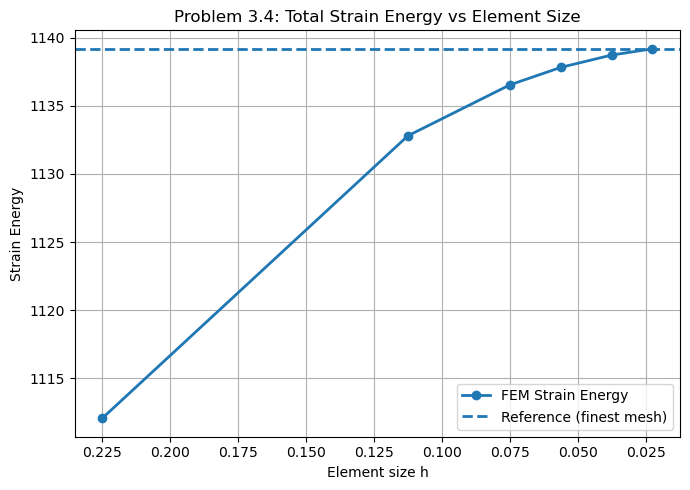


Saved plot as "Problem_3_4_Strain_Energy_Convergence.pdf".


In [16]:
# ============================================================
#   Compute FEM Strain Energy
# ============================================================
def compute_strain_energy(Connectivity, Coord, U, EleType, NGPTS, medium_set):
    """
    Computes FEM strain energy using the same Kronecker-based grad(u)
    concept as in Stress_Recovery_AvgNodes_2D.

    - Plane strain formulation
    - Strain vector: [eps_xx, eps_yy, gamma_xy]
        where
          eps_xx = u_x,x
          eps_yy = u_y,y
          gamma_xy = u_x,y + u_y,x   (engineering shear).
    """
    Nele, nnode = Connectivity.shape

    # Material parameters (these lambdas/mu are 3D Lame parameters)
    lam = medium_set["lambda"]
    mu  = medium_set["mu"]

    # Plane-strain elasticity matrix [eps_xx, eps_yy, gamma_xy]
    D = np.array([
        [lam + 2*mu, lam,         0.0],
        [lam,        lam + 2*mu,  0.0],
        [0.0,        0.0,         mu ]
    ])

    # Gauss rule
    r, w = GaussPoints(2, EleType, NGPTS)   # r: (ngauss,2), w: (ngauss,)
    ngauss = len(w)

    total_energy = 0.0
    I2 = np.eye(2)

    for e in range(Nele):
        # Element connectivity and local fields
        nodes = Connectivity[e, :] - 1          # 0-based
        xCap  = Coord[nodes, :]                # (nnode x 2)
        Ucap  = U[nodes, :]                    # (nnode x 2)

        # Vectorized displacement (2*nnode x 1), col-major:
        # [ux1, ux2, ..., ux_nnode, uy1, ..., uy_nnode]^T
        Ucap_vec = Vector(Ucap.T)

        for g in range(ngauss):
            zeta_eta = r[g, :]                 # [xi, eta]
            N, DN = ShapeFunctions(EleType, zeta_eta)

            # Jacobian
            J    = xCap.T @ DN                 # (2x2)
            detJ = np.linalg.det(J)
            invJ = np.linalg.inv(J)

            # dN/dx, dN/dy
            B = DN @ invJ                   # (nnode x 2)

            # grad u via Kronecker:
            # vec(grad u) = (dNdx^T kron I2) vec(Ucap)
            BT_kron_I = np.kron(B.T, I2)    # (4 x 2*nnode)
            gradu_vec = BT_kron_I @ Ucap_vec   # (4 x 1)

            # gradu_vec = [u_x,x, u_y,x, u_x,y, u_y,y]^T
            ux_x = gradu_vec[0, 0]
            uy_x = gradu_vec[1, 0]
            ux_y = gradu_vec[2, 0]
            uy_y = gradu_vec[3, 0]

            # Voigt strain vector [eps_xx, eps_yy, gamma_xy]
            eps_xx    = ux_x
            eps_yy    = uy_y
            gamma_xy  = ux_y + uy_x    # engineering shear

            strain = np.array([eps_xx, eps_yy, gamma_xy])

            # Stress in Voigt form
            stress = D @ strain

            # Strain energy density: 1/2 * sigma^T * eps
            W = 0.5 * np.dot(stress, strain)

            # Add Gauss-point contribution (per unit thickness)
            total_energy += W * detJ * w[g]

    return total_energy


# ============================================================
#   3.4 — Mesh Refinement Study
# ============================================================
def run_problem_3_4():

    ri = 0.1
    ro = 1.0
    u0 = 0.05
    E = 1e5
    nu = 0.3

    Nr_list = [4, 8, 12, 16, 24, 40]
    Ntheta_scale = 4          

    hs = []
    energies = []

    for Nr in Nr_list:
        Ntheta = Ntheta_scale * Nr
        h = (ro - ri) / Nr
        hs.append(h)

        print(f"\n=== Mesh Nr={Nr}, Ntheta={Ntheta}, h={h:.4f} ===")

        Coord, Conn, Cons, mat, load = generate_full_cylinder_Q4_mesh(
            ri, ro, Nr, Ntheta, E, nu, u0
        )

        NumNodes = Coord.shape[0]
        Nele = Conn.shape[0]

        U = Driver_LE(
            Conn, Cons, Coord,
            mat, 2, 2,
            "Q4", load,
            Cons.shape[0], Nele, 2, NumNodes, None
        )

        Pi_h = compute_strain_energy(Conn, Coord, U, "Q4", 2, mat)

        print(f"Strain energy = {Pi_h:.6f}")

        energies.append(Pi_h)

    

    # Convert to numpy
    hs = np.array(hs)
    energies = np.array(energies)
    
    Pi_ref = energies[-1]
    
    print(" hs =", hs)
    print(" energies =", energies)
    print(" Pi_ref =", Pi_ref)

    plt.figure(figsize=(7,5))
    plt.plot(hs, energies, 'o-', linewidth=2, label="FEM Strain Energy")
    plt.axhline(Pi_ref, linestyle='--', linewidth=2,
                label="Reference (finest mesh)")
    plt.gca().invert_xaxis()
    
    plt.xlabel("Element size h")
    plt.ylabel("Strain Energy")
    plt.title("Problem 3.4: Total Strain Energy vs Element Size")
    
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig("Problem_3_4_Strain_Energy_Convergence.pdf")
    plt.show()

    
    print('\nSaved plot as "Problem_3_4_Strain_Energy_Convergence.pdf".')

# ============================================================
#   MAIN
# ============================================================
if __name__ == "__main__":
    run_problem_3_4()



 Problem 3.5: L2 Error Convergence (Elasticity)

=== Mesh Nr=4, Ntheta=16, h=0.2250 ===

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (80, 2),   NEqns = 96

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (64, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (96, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (80, 2)

Linear elasticity simulation completed successfully.

L2 displacement error = 3.497313e-04

=== Mesh Nr=8, Ntheta=32, h=0.1125 ===

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (288, 2),   NEqns = 448

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (128, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (448, 1)

Step 5: 

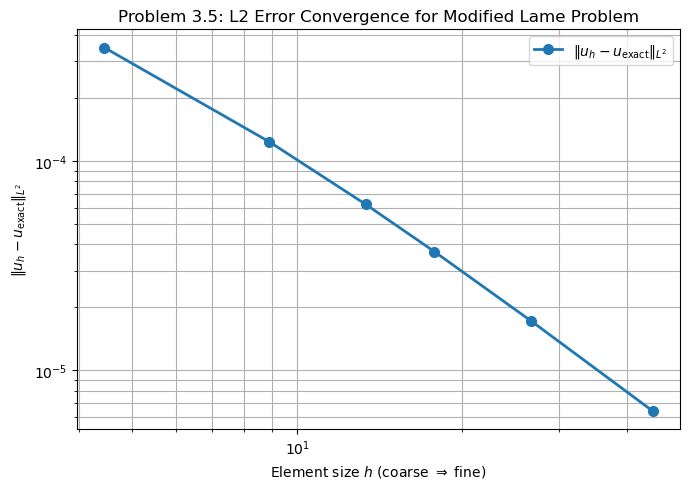


Saved plot as "Problem_3_5_L2_Error_Convergence.pdf".


In [17]:
def exact_disp_cartesian(x, ri, ro, u0):
    """
    Exact displacement vector u_exact(x,y) in Cartesian coordinates,
    derived from radial solution u_r(r) and direction e_r = (x/r, y/r).
    """
    x = np.asarray(x)
    xx, yy = x
    r = np.sqrt(xx**2 + yy**2)
    # Avoid divide-by-zero at r=0 
    if r == 0.0:
        return np.array([0.0, 0.0])

    ur = u_r_exact(r, ri, ro, u0)
    ex = xx / r
    ey = yy / r
    return np.array([ur * ex, ur * ey])


# ------------------------------------------------------------
# 2. Problem 3.5: L2 error convergence study
# ------------------------------------------------------------
def run_problem_3_5():

    # Geometry / material (same as 3.3, 3.4)
    ri = 0.1
    ro = 1.0
    u0 = 0.05
    E = 1e5
    nu = 0.3

    # Mesh refinements (coarse to fine)
    Nr_list = [4, 8, 12, 16, 24, 40]
    Ntheta_scale = 4   # keep aspect ratio reasonable

    hs = []
    errors_L2 = []

    print("\n==============================================")
    print(" Problem 3.5: L2 Error Convergence (Elasticity)")
    print("==============================================")

    for Nr in Nr_list:
        Ntheta = Ntheta_scale * Nr
        h = (ro - ri) / Nr     # characteristic radial element size
        hs.append(h)

        print(f"\n=== Mesh Nr={Nr}, Ntheta={Ntheta}, h={h:.4f} ===")

        # Generate mesh & FEM inputs (from your 3.3 code)
        Coord, Conn, Cons, mat, load = generate_full_cylinder_Q4_mesh(
            ri, ro, Nr, Ntheta, E, nu, u0
        )

        NumNodes = Coord.shape[0]
        Nele = Conn.shape[0]

        # Solve elasticity problem
        U = Driver_LE(
            Conn, Cons, Coord,
            mat, 2, 2,
            "Q4", load,
            Cons.shape[0], Nele, 2, NumNodes, None
        )

        # Wrap exact displacement as a function of x for error routine
        def get_exact_disp(x):
            return exact_disp_cartesian(x, ri, ro, u0)

        # Compute L2 displacement error
        err_L2 = Calculate_Error_Elasticity(
            Conn, Coord,
            "Q4", 2,
            U,
            get_exact_disp,
            verbose=False
        )

        print(f"L2 displacement error = {err_L2:.6e}")
        errors_L2.append(err_L2)

    # Convert to arrays (order is coarse to fine; no sorting needed)
    hs = np.array(hs)
    errors_L2 = np.array(errors_L2)

    # --------------------------------------------------------
    # Compute convergence rate (slope) from log-log regression
    # --------------------------------------------------------
    logh = np.log(hs)
    loge = np.log(errors_L2)
    
    # Fit slope: log(e) = slope * log(h) + C
    slope, intercept = np.polyfit(logh, loge, 1)
    
    print("\n==============================================")
    print(" Empirical Convergence Rate for L2 Error")
    print("==============================================")
    print(f"  Slope p = {slope:.4f}  (expected = 2.0 for Q4)")
    print("==============================================\n")

    # --------------------------------------------------------
    # Plot: L2 error vs element size h (log–log)
    # --------------------------------------------------------
    plt.figure(figsize=(7, 5))
    plt.loglog(1/hs, errors_L2, 'o-', linewidth=2, markersize=7,
               label=r"$\|u_h - u_{\text{exact}}\|_{L^2}$")

    plt.xlabel("Element size $h$ (coarse $\Rightarrow$ fine)")
    plt.ylabel(r"$\|u_h - u_{\text{exact}}\|_{L^2}$")
    plt.title("Problem 3.5: L2 Error Convergence for Modified Lame Problem")
    plt.grid(True, which='both')
    plt.legend()

    # Annotate slope
    #plt.text(hs[1], errors_L2[1], f"p ≈ {slope:.2f}", fontsize=12)
    plt.tight_layout()
    plt.savefig("Problem_3_5_L2_Error_Convergence.pdf")
    plt.show()

    print('\nSaved plot as "Problem_3_5_L2_Error_Convergence.pdf".')


# ------------------------------------------------------------
# 3. Main guard to run the study when script is executed
# ------------------------------------------------------------
if __name__ == "__main__":
    run_problem_3_5()

# ------------------------------------------------------

## Solving a BVP with no Analytical Solution

# ------------------------------------------------------

### 4. Cook's Problem


===== Mesh 2 x 2 =====

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (9, 2),   NEqns = 12

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (6, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (12, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (9, 2)

Linear elasticity simulation completed successfully.

Vertical displacement at A = 8.135942e+01

===== Mesh 4 x 4 =====

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (25, 2),   NEqns = 40

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (10, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F –

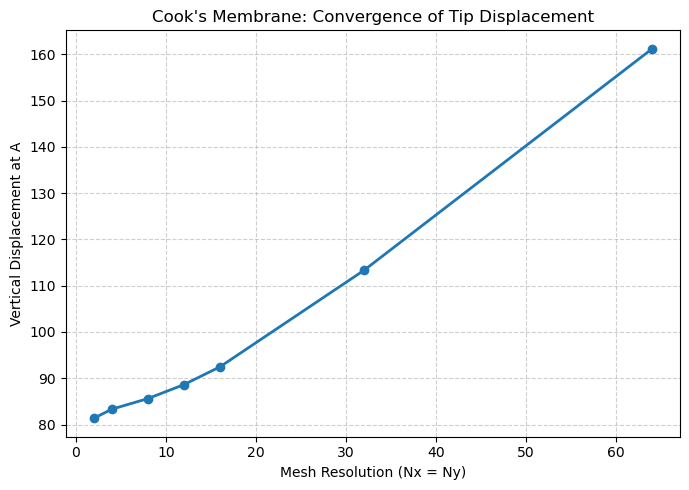

In [18]:
# ------------------------------------------------------------
#  Cook’s Membrane — Geometry Coordinates
# ------------------------------------------------------------
# Based on your corrected interpretation:
#    D = (0,0)
#    B = (24,44)
#    C = (24,60)
#    A = (48,60)

def cook_coordinates():
    """
    Cook's membrane corners:
      D = (0, 0)   bottom left
      C = (0, 44)  top left
      B = (48,44)  bottom right
      A = (48,60)  top right (load edge)
    """
    D = np.array([0.0,  0.0])   # bottom left
    C = np.array([0.0, 44.0])   # top  left
    B = np.array([48.0,44.0])   # bottom right
    A = np.array([48.0,60.0])   # top right
    return A, B, C, D


# ------------------------------------------------------------
#  Generate Q4 Mesh for Cook’s Membrane (Structured)
# ------------------------------------------------------------
def generate_cook_mesh(Nx, Ny):
    A, B, C, D = cook_coordinates()

    # Local Q4 order: (-1,-1),(1,-1),(1,1),(-1,1)
    # Map these to: 1-D, 2-B, 3-A, 4-C
    P = np.vstack([D, B, A, C])

    xi  = np.linspace(-1, 1, Nx+1)
    eta = np.linspace(-1, 1, Ny+1)

    Coord = []
    for j in range(Ny+1):
        for i in range(Nx+1):
            N1 = 0.25*(1-xi[i])*(1-eta[j])
            N2 = 0.25*(1+xi[i])*(1-eta[j])
            N3 = 0.25*(1+xi[i])*(1+eta[j])
            N4 = 0.25*(1-xi[i])*(1+eta[j])
            x = N1*P[0] + N2*P[1] + N3*P[2] + N4*P[3]
            Coord.append(x)

    Coord = np.array(Coord)

    # connectivity same as before
    Conn = []
    for j in range(Ny):
        for i in range(Nx):
            n1 = j*(Nx+1) + i + 1
            n2 = n1 + 1
            n3 = n1 + Nx + 2
            n4 = n1 + Nx + 1
            Conn.append([n1, n2, n3, n4])
    Conn = np.array(Conn, dtype=int)

    return Coord, Conn


# ------------------------------------------------------------
#  Apply BCs: Left Edge Fixed
# ------------------------------------------------------------
def cook_constraints(Coord):
    tol = 1e-8
    left_nodes = np.where(np.abs(Coord[:,0]) < tol)[0]

    Cons = []
    for n in left_nodes:
        Cons.append([n+1, 1, 0.0])  # Ux = 0
        Cons.append([n+1, 2, 0.0])  # Uy = 0
    return np.array(Cons, float)


# ------------------------------------------------------------
#  Apply Traction on Edge AB (vertical traction = 100)
# ------------------------------------------------------------
def cook_edge_load(Coord):
    V = 100.0          # traction [force/length]
    L = 16.0           # loaded length
    F_total = V * L    # 1600

    # Find nodes on x = 48 in the loaded vertical segment 44 <= y <= 60
    right_nodes = np.where(np.isclose(Coord[:, 0], 48.0))[0]
    yvals = Coord[right_nodes, 1]
    mask = (yvals >= 44.0) & (yvals <= 60.0)
    load_nodes = right_nodes[mask]

    # Sort from bottom to top
    load_nodes = load_nodes[np.argsort(Coord[load_nodes, 1])]

    n = len(load_nodes)
    if n < 2:
        raise RuntimeError("Not enough nodes on Cook's loaded edge")

    # Segment load q Δs
    Pint = F_total / (n - 1)   # = V * (L/(n-1))

    ptload = []
    for k, node in enumerate(load_nodes):
        if k == 0 or k == n - 1:
            val = 0.5 * Pint   # end nodes: P_end = Pint/2
        else:
            val = Pint         # interior nodes: Pint
        ptload.append([node + 1, 2, val])  # DOF=2 = vertical

    return np.array(ptload, float)





# ------------------------------------------------------------
# FULL SOLVER FOR 4.1
# ------------------------------------------------------------
def run_cook_4_1():

    E = 100
    nu = 0.4999

    medium_set = {
        "type": "Lame_params",
        "lambda": E*nu/((1+nu)*(1-2*nu)),
        "mu": E/(2*(1+nu))
    }

    mesh_list = [(2,2),(4,4),(8,8),(12,12),(16,16),(32,32),(64,64)]

    dispA = []

    for Nx, Ny in mesh_list:
        print(f"\n===== Mesh {Nx} x {Ny} =====")

        Coord, Conn = generate_cook_mesh(Nx,Ny)
        Cons = cook_constraints(Coord)

        NumNodes = Coord.shape[0]
        Nele = Conn.shape[0]

        load_type = {"case": "2D_gravity", "rhob": 0.0}

        ptload = cook_edge_load(Coord)

        U = Driver_LE(
            Conn, Cons, Coord,
            medium_set, 2, 2,
            "Q4", load_type,
            Cons.shape[0], Nele, 2, NumNodes,
            ptload
        )

        # TIP = point A (48,60)
        A,_,_,_ = cook_coordinates()
        nodeA = np.argmin(np.linalg.norm(Coord - A, axis=1))
        dispA.append(U[nodeA,1])

        print(f"Vertical displacement at A = {U[nodeA,1]:.6e}")

    # Print results summary
    print("\n===== FINAL RESULTS =====")
    for (Nx,Ny), uy in zip(mesh_list, dispA):
        print(f"{Nx}x{Ny}: uy(A) = {uy:.6e}")

    # ------------------------------------------------------------
    # Convergence Plot: Vertical Displacement at Tip A
    # ------------------------------------------------------------
    # Use number of elements (Nx) as horizontal axis
    mesh_sizes = [Nx for (Nx, Ny) in mesh_list]

    plt.figure(figsize=(7,5))
    plt.plot(mesh_sizes, dispA, 'o-', linewidth=2, markersize=6)

    plt.xlabel("Mesh Resolution (Nx = Ny)")
    plt.ylabel("Vertical Displacement at A")
    plt.title("Cook's Membrane: Convergence of Tip Displacement")
    plt.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.savefig("cook_convergence_plot.pdf")
    plt.show()

# ------------------------------------------------------------
# RUN
# ------------------------------------------------------------
if __name__ == "__main__":
    run_cook_4_1()


In [19]:
def Stress_Recovery_AvgNodes_2D(Connectivity, Coord, U, medium_set):
    """
    Computes nodal stresses for 2D Q4 plane-strain elements using
    the Kronecker-product formulation:

        vec(grad u) = kron(B^T , I2) vec(Ucap),

    and then forming the *same* Voigt strain vector as in the
    original B-matrix code:

        [eps_xx, eps_yy, gamma_xy]^T
        = [u_x,x, u_y,y, u_x,y + u_y,x]^T

    Returns
    -------
    sigma_nodes : (NumNodes x 3)
        columns = [ x, y, trT ]
    """

    NumNodes = Coord.shape[0]
    Nele, NodesPerEle = Connectivity.shape

    trT_accum   = np.zeros(NumNodes)
    count_accum = np.zeros(NumNodes)

    lam = medium_set["lambda"]
    mu  = medium_set["mu"]

    I2 = np.eye(2)

    # Q4 reference coords (xi, eta) for the 4 corner nodes
    ref_coords = np.array([
        [-1.0, -1.0],
        [ 1.0, -1.0],
        [ 1.0,  1.0],
        [-1.0,  1.0]
    ])

    for e in range(Nele):

        nodes = Connectivity[e, :] - 1      # 0-based node indices
        xCap  = Coord[nodes, :]            # (4 x 2)
        Ucap  = U[nodes, :]                # (4 x 2), rows: node, cols: [ux,uy]

        # vectorized displacement (8 x 1), col-major:
        # [ux1, ux2, ux3, ux4, uy1, uy2, uy3, uy4]^T
        Ucap_vec = Vector(Ucap.T)

        for loc_node, (xi, eta) in enumerate(ref_coords):

            # shape functions & derivatives in reference coords
            N, dN = ShapeFunctions("Q4", np.array([xi, eta]))   # dN: (4x2)

            # Jacobian and spatial derivatives
            J    = xCap.T @ dN          # (2x2)
            invJ = np.linalg.inv(J)
            B    = dN @ invJ            # (4x2), gradients of N in x,y

            # grad u as a 4x1 vector:
            # vec(grad u) = [u_x,x, u_y,x, u_x,y, u_y,y]^T
            BT_kron_I = np.kron(B.T, I2)      # (4x8)
            gradu_vec = BT_kron_I @ Ucap_vec  # (4x1)

            ux_x = gradu_vec[0, 0]
            uy_x = gradu_vec[1, 0]
            ux_y = gradu_vec[2, 0]
            uy_y = gradu_vec[3, 0]

            # MATCH ORIGINAL IMPLEMENTATION:
            # Voigt strain vector [eps_xx, eps_yy, gamma_xy]
            eps_xx = ux_x
            eps_yy = uy_y
            gamma_xy = ux_y + uy_x     # engineering shear

            # plane-strain stresses 
            sigma_xx = (lam + 2*mu) * eps_xx + lam * eps_yy
            sigma_yy = lam * eps_xx + (lam + 2*mu) * eps_yy
            sigma_zz = lam * (eps_xx + eps_yy)  # plane strain σ_zz

            trT = sigma_xx + sigma_yy + sigma_zz

            gid = nodes[loc_node]
            trT_accum[gid] += trT
            count_accum[gid] += 1

    trT_avg = trT_accum / np.maximum(count_accum, 1)

    sigma_nodes = np.zeros((NumNodes, 3))
    sigma_nodes[:, 0:2] = Coord
    sigma_nodes[:, 2]   = trT_avg 

    return sigma_nodes


In [20]:
def extract_trT_on_BC_from_nodes(Coord, sigma_nodes, tol=1e-6):
    """
    Extract tr[T] along BC from nodal stress field.

    BC is the vertical line:
        x = 24
        y in [22, 52]
    """

    x = Coord[:,0]
    y = Coord[:,1]
    trT = sigma_nodes[:,2]

    mask = (np.abs(x - 24.0) < tol) & (y >= 22.0) & (y <= 52.0)
    bc_nodes = np.where(mask)[0]

    # sort by y
    order = np.argsort(y[bc_nodes])

    y_line  = y[bc_nodes][order]
    trT_line = trT[bc_nodes][order]

    return y_line, trT_line


In [21]:
def run_cook_4_2():

    # material
    E  = 100.0
    nu = 0.4999
    lam = E*nu/((1+nu)*(1-2*nu))
    mu  = E/(2*(1+nu))

    medium_set = {
        "type": "Lame_params",
        "lambda": lam,
        "mu": mu
    }

    # mesh
    Nx, Ny = 64, 64
    Coord, Conn = generate_cook_mesh(Nx, Ny)
    Cons        = cook_constraints(Coord)
    ptload      = cook_edge_load(Coord)

    NumNodes = Coord.shape[0]
    Nele     = Conn.shape[0]

    load_type = {"case": "2D_gravity", "rhob": 0.0}

    # solve displacement
    U = Driver_LE(
        Conn, Cons, Coord,
        medium_set, 2, 2,
        "Q4", load_type,
        Cons.shape[0], Nele, 2, NumNodes,
        ptload
    )

    # ------------------------------------------------------------------
    # 1) Compute nodal stresses (averaged)
    # ------------------------------------------------------------------
    sigma_nodes = Stress_Recovery_AvgNodes_2D(Conn, Coord, U, medium_set)

    # ------------------------------------------------------------------
    # 2) Extract tr[T] along BC
    # ------------------------------------------------------------------
    y_vals, trT_vals = extract_trT_on_BC_from_nodes(Coord, sigma_nodes)

    # ------------------------------------------------------------------
    # 3) Plot
    # ------------------------------------------------------------------
    plt.figure(figsize=(6,4))
    plt.plot(y_vals, trT_vals, 'o-', linewidth=2)
    plt.xlabel("y-coordinate along BC")
    plt.ylabel("tr[T]")
    plt.title("Cook’s Problem – trace(T) along BC (nodal averaging)")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("Cook_4_2_trT_BC_nodes.pdf")
    plt.show()

    print("\nSaved: Cook_4_2_trT_BC_nodes.pdf")



 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (4225, 2),   NEqns = 8320

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (130, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (8320, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (4225, 2)

Linear elasticity simulation completed successfully.



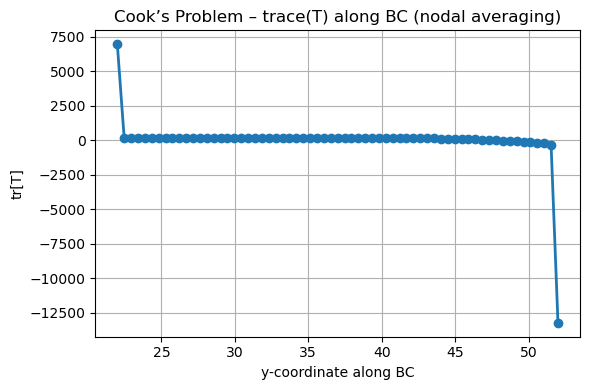


Saved: Cook_4_2_trT_BC_nodes.pdf


In [22]:
if __name__ == "__main__": 
    run_cook_4_2()

In [23]:
def run_cook_4_3():
    """
    Problem 4.3:
        For the finest mesh used in 4.1 (here: 64 x 64),
        plot the vertical tip displacement at A as a function
        of Poisson's ratio nu.

        nu values: 0, 0.1, 0.25, 0.4, 0.45, 0.49, 0.4999
    """

    # --------------------------------------------------------
    # 1. Problem / mesh setup
    # --------------------------------------------------------
    E = 100.0   # as in project statement

    # Finest mesh used in 4.1
    Nx = 64
    Ny = 64

    # Generate mesh, constraints, and edge loads ONCE
    Coord, Conn = generate_cook_mesh(Nx, Ny)
    Cons        = cook_constraints(Coord)
    ptload      = cook_edge_load(Coord)

    NumNodes = Coord.shape[0]
    Nele     = Conn.shape[0]

    load_type = {"case": "2D_gravity", "rhob": 0.0}

    # Find node index closest to point A (48,60)
    A, _, _, _ = cook_coordinates()
    nodeA = np.argmin(np.linalg.norm(Coord - A, axis=1))

    # --------------------------------------------------------
    # 2. Loop over Poisson's ratio values
    # --------------------------------------------------------
    nu_list = [0.0, 0.1, 0.25, 0.4, 0.45, 0.49, 0.4999]
    uyA_list = []

    print("\n=== Cook 4.3: Tip displacement at A vs Poisson's ratio ===")
    print(f"Mesh: {Nx} x {Ny}, E = {E}")

    for nu in nu_list:
        # Lame parameters for given nu
        lam = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu)) if nu != 0.5 else 1e15
        mu  = E / (2.0 * (1.0 + nu))

        medium_set = {
            "type": "Lame_params",
            "lambda": lam,
            "mu": mu
        }

        print(f"\n--- Solving for nu = {nu:.4f} ---")

        U = Driver_LE(
            Conn, Cons, Coord,
            medium_set, 2, 2,
            "Q4", load_type,
            Cons.shape[0], Nele, 2, NumNodes,
            ptload
        )

        # vertical displacement at tip A (nodeA, y-direction)
        uyA = U[nodeA, 1]
        uyA_list.append(uyA)

        print(f"  Vertical tip displacement at A: uy(A) = {uyA:.6e}")

    # --------------------------------------------------------
    # 3. Print summary table
    # --------------------------------------------------------
    print("\n===== SUMMARY: Tip displacement at A vs Poisson's ratio =====")
    for nu, uyA in zip(nu_list, uyA_list):
        print(f"nu = {nu:7.4f}  ->  uy(A) = {uyA:.6e}")

    # --------------------------------------------------------
    # 4. Plot uy(A) vs nu
    # --------------------------------------------------------
    plt.figure(figsize=(6,4))
    plt.plot(nu_list, uyA_list, 'o-', linewidth=2)
    plt.xlabel(r"Poisson's ratio $\nu$")
    plt.ylabel(r"Vertical tip displacement $u_y(A)$")
    plt.title("Cook's Problem – Tip displacement at A vs Poisson's ratio")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("Cook_4_3_tip_disp_vs_nu.pdf")
    plt.show()

    print('\nSaved "Cook_4_3_tip_disp_vs_nu.pdf".')



=== Cook 4.3: Tip displacement at A vs Poisson's ratio ===
Mesh: 64 x 64, E = 100.0

--- Solving for nu = 0.0000 ---

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (4225, 2),   NEqns = 8320

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (130, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (8320, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (4225, 2)

Linear elasticity simulation completed successfully.

  Vertical tip displacement at A: uy(A) = 3.900914e+02

--- Solving for nu = 0.1000 ---

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (4225, 2),   NEqns = 8320

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (130, 1)

Step 3: Calculating Global Stiffness Matrix a

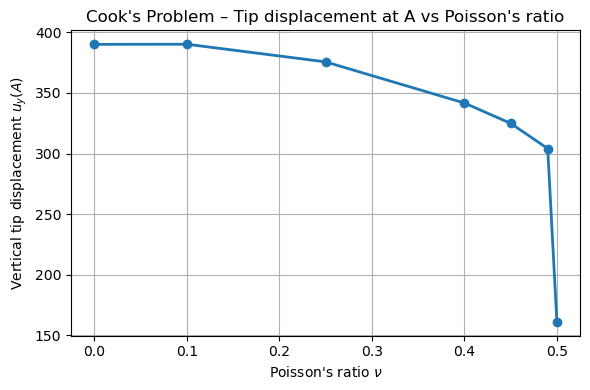


Saved "Cook_4_3_tip_disp_vs_nu.pdf".


In [24]:
if __name__ == "__main__": 
    run_cook_4_3()

# -------------------------------------------------

## Design Charts

# -------------------------------------------------

In [25]:
def generate_plate_with_hole_Q4(H, L, d, nx, ny):
    """
    Generate a structured Q4 mesh for a finite-width plate with a
    central circular hole (SCF geometry).

    Geometry (in x–y):
        - Plate length: L  (0 .. L)
        - Plate height: H  (-H/2 .. +H/2)
        - Circular hole centered at (L/2, 0) with diameter d

    Discretization:
        - nx: number of nodes along x
        - ny: number of nodes along y
        - Elements are axis-aligned Q4.
        - Elements whose centroid lies inside the hole (r < d/2)
          are removed.

    Returns
    -------
    Coord : (NumNodes, 2) float
        Node coordinates [x, y].
        Indexing is 0-based (Coord[i] is node i+1).
    Connectivity : (Nele, 4) int
        Q4 connectivity in counter-clockwise order.
        **Node IDs are 1-based**, i.e., in [1, NumNodes].
    LeftNodes, RightNodes, TopNodes, BottomNodes, HoleNodes : 1D int arrays
        Node IDs (1-based) for edges / hole.
    hole_center : (2,) float
    hole_radius : float
    """

    if nx < 2 or ny < 2:
        raise ValueError("nx and ny must be >= 2")

    # -------------------------------------------------
    # 1. Structured grid of nodes (full rectangle)
    # -------------------------------------------------
    x = np.linspace(0.0, L, nx)
    y = np.linspace(-H / 2.0, H / 2.0, ny)

    X, Y = np.meshgrid(x, y)        # shape (ny, nx)
    Coord_full = np.column_stack([X.ravel(), Y.ravel()])  # (nx*ny, 2)

    # node_id(i,j) -> 1-based node ID
    def node_id(i, j):
        # i: 0..nx-1, j: 0..ny-1
        return j * nx + i + 1

    a = d / 2.0
    xc, yc = L / 2.0, 0.0
    hole_center = np.array([xc, yc], float)
    hole_radius = a

    # radius of all full-grid nodes
    r_full = np.hypot(Coord_full[:, 0] - xc,
                      Coord_full[:, 1] - yc)
    nodes_in_hole = r_full < a   # boolean mask

    # -------------------------------------------------
    # 2. Build Q4 elements and remove those that touch
    #    any node strictly inside the hole.
    # -------------------------------------------------
    elems = []

    for j in range(ny - 1):
        for i in range(nx - 1):
            n1 = node_id(i,     j)
            n2 = node_id(i + 1, j)
            n3 = node_id(i + 1, j + 1)
            n4 = node_id(i,     j + 1)

            # if ANY corner node is inside the hole → drop this element
            if (nodes_in_hole[n1 - 1] or
                nodes_in_hole[n2 - 1] or
                nodes_in_hole[n3 - 1] or
                nodes_in_hole[n4 - 1]):
                continue

            elems.append([n1, n2, n3, n4])

    if not elems:
        raise RuntimeError("All elements removed – check H, L, d, nx, ny")

    elems = np.array(elems, dtype=int)

    # -------------------------------------------------
    # 3. Compress node numbering 
    # -------------------------------------------------
    used_nodes = np.unique(elems.ravel())
    NumNodes = used_nodes.size

    max_id = used_nodes.max()
    new_id = np.zeros(max_id + 1, dtype=int)
    new_id[used_nodes] = np.arange(1, NumNodes + 1)

    Coord = Coord_full[used_nodes - 1, :]
    Connectivity = new_id[elems]
    # -------------------------------------------------
    # 4. Identify boundary nodes (1-based IDs)
    # -------------------------------------------------
    xC = Coord[:, 0]
    yC = Coord[:, 1]

    tolx = 1e-10 * max(1.0, L)
    toly = 1e-10 * max(1.0, H)

    left_mask   = np.abs(xC - 0.0) < tolx
    right_mask  = np.abs(xC - L)   < tolx
    bottom_mask = np.abs(yC + H/2) < toly
    top_mask    = np.abs(yC - H/2) < toly

    LeftNodes   = np.where(left_mask)[0]
    RightNodes  = np.where(right_mask)[0]
    BottomNodes = np.where(bottom_mask)[0]
    TopNodes    = np.where(top_mask)[0]

    # sort them nicely (Bottom/Top: left->right, Left/Right: bottom->top)
    LeftNodes   = LeftNodes[np.argsort(yC[LeftNodes])]   + 1
    RightNodes  = RightNodes[np.argsort(yC[RightNodes])] + 1
    BottomNodes = BottomNodes[np.argsort(xC[BottomNodes])] + 1
    TopNodes    = TopNodes[np.argsort(xC[TopNodes])]       + 1

    # ---------------------------------------
    # 5. Identify true hole-boundary nodes
    #    i.e. nodes near the innermost element ring
    # ---------------------------------------
    xC = Coord[:, 0]
    yC = Coord[:, 1]

    # Element centroids (Connectivity is Nele x 4, 1-based)
    elem_centers = Coord[Connectivity - 1].mean(axis=1)  # (Nele, 2)
    r_elem = np.hypot(elem_centers[:, 0] - xc,
                      elem_centers[:, 1] - yc)

    # This is the radius of the FE hole boundary
    r_hole = r_elem.min()

    # Nodal radii
    rC = np.hypot(xC - xc, yC - yc)

    dx = L / (nx - 1)
    dy = H / (ny - 1)
    hmin = min(dx, dy)

    # Tolerance band around r_hole
    tol = 0.8 * hmin

    hole_mask = np.abs(rC - r_hole) <= tol
    HoleNodes = np.where(hole_mask)[0] + 1   # 1-based

    return (Coord, Connectivity,
            LeftNodes, RightNodes, TopNodes, BottomNodes,
            HoleNodes, hole_center, hole_radius)


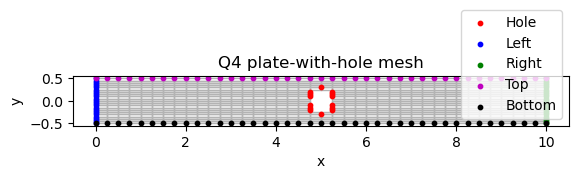

In [26]:
if __name__ == "__main__":
    from matplotlib.collections import PolyCollection

    H = 1.0
    Hmax = 2.0
    L = 5 * Hmax
    d = 0.5

    nx, ny = 41, 21

    (Coord, Connectivity,
     LeftNodes, RightNodes, TopNodes, BottomNodes,
     HoleNodes, hole_center, hole_radius) = generate_plate_with_hole_Q4(H, L, d, nx, ny)

    # Build polygons for plotting
    polys = []
    for e in Connectivity:
        # e has 1-based IDs, convert to 0-based indices
        pts = Coord[e - 1, :]
        polys.append(pts)

    fig, ax = plt.subplots()
    pc = PolyCollection(polys, facecolors='none', edgecolors='0.7')
    ax.add_collection(pc)
    ax.scatter(Coord[HoleNodes - 1, 0],   Coord[HoleNodes - 1, 1],   s=10, c='r', label='Hole')
    ax.scatter(Coord[LeftNodes - 1, 0],   Coord[LeftNodes - 1, 1],   s=10, c='b', label='Left')
    ax.scatter(Coord[RightNodes - 1, 0],  Coord[RightNodes - 1, 1],  s=10, c='g', label='Right')
    ax.scatter(Coord[TopNodes - 1, 0],    Coord[TopNodes - 1, 1],    s=10, c='m', label='Top')
    ax.scatter(Coord[BottomNodes - 1, 0], Coord[BottomNodes - 1, 1], s=10, c='k', label='Bottom')

    ax.set_aspect('equal', 'box')
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Q4 plate-with-hole mesh")
    ax.legend(loc="best")
    plt.show()


In [27]:
def build_edge_traction_loads(Coord, edge_node_ids, traction, dof_index):
    """
    Build nodal point loads for a constant traction applied along a straight edge,
    using the same ideology as your Cook example:
        - Total force = traction * edge_length
        - N nodes => N-1 segments
        - Each segment gets q * Δs
        - End nodes get half of one segment's load, interior nodes get full.

    Parameters
    ----------
    Coord : (NumNodes, 2) float
        Node coordinates, 0-based indexing.
    edge_node_ids : (N,) int
        Node IDs on the loaded edge (1-based). Can be unsorted.
    traction : float
        Magnitude of traction [force / length].
    dof_index : int
        DOF index in the global load vector (1=x, 2=y).

    Returns
    -------
    ptload : (N, 3) float
        Each row: [nodeID (1-based), dof_index, nodal_force]
    """

    edge_node_ids = np.asarray(edge_node_ids, dtype=int)
    if edge_node_ids.size < 2:
        raise ValueError("Need at least two nodes on the edge.")

    # convert to 0-based
    idx0 = edge_node_ids - 1
    coords = Coord[idx0, :]  # (N,2)

    # ------------------------------------------------------------
    #  Determine orientation (vertical-ish or horizontal-ish)
    # ------------------------------------------------------------
    dx_span = np.ptp(coords[:, 0])     # use np.ptp
    dy_span = np.ptp(coords[:, 1])

    if dy_span >= dx_span:
        # vertical edge → sort by y
        order = np.argsort(coords[:, 1])
        param = coords[order, 1]
    else:
        # horizontal edge → sort by x
        order = np.argsort(coords[:, 0])
        param = coords[order, 0]

    # sorted 1-based node IDs
    sorted_ids = edge_node_ids[order]

    # ------------------------------------------------------------
    #  Compute edge length and nodal loads
    # ------------------------------------------------------------
    L = float(param[-1] - param[0])
    if L <= 0:
        raise RuntimeError("Degenerate edge length.")

    F_total = traction * L
    N = sorted_ids.size
    Pint = F_total / (N - 1)  # segment load

    nodal_forces = np.zeros(N, float)
    for k in range(N):
        if k == 0 or k == N - 1:
            nodal_forces[k] = 0.5 * Pint
        else:
            nodal_forces[k] = Pint

    # ------------------------------------------------------------
    #  Construct [nodeID, dof_index, value]
    # ------------------------------------------------------------
    ptload = np.column_stack([
        sorted_ids.astype(float),
        np.full(N, float(dof_index)),
        nodal_forces,
    ])

    return ptload


In [28]:
def build_SCF_point_loads(Coord, LeftNodes, RightNodes, sigma, constrained_nodes=None):
    """
    Build nodal point loads for the stress concentration factor (SCF) problem.
    
    Traction pattern:
        - LEFT edge receives +sigma (tension pulling right)
        - RIGHT edge receives -sigma (tension pulling left)
    
    Loads are applied purely in the x-direction (dof_index = 1)
    using the Cook-style integrated traction approach.
    
    Parameters
    ----------
    Coord : (NumNodes, 2) float
        Node coordinates (0-based indexing).
    
    LeftNodes : (N1,) int
        Node IDs (1-based) on the left edge (x = 0).
    
    RightNodes : (N2,) int
        Node IDs (1-based) on the right edge (x = L).
    
    sigma : float
        Applied traction magnitude (force per unit length).
    
    Returns
    -------
    Point_loads : (K, 3) float
        Rows are [nodeID (1-based), dof_index, nodal_force].
    """
    # if constrained_nodes is None:
    #     constrained_nodes = set()
    # else:
    #     constrained_nodes = set(int(n) for n in constrained_nodes)

    # def filtered(nodes):
    #     return [n for n in nodes if n not in constrained_nodes]

    # LeftNodes  = filtered(LeftNodes)
    # RightNodes = filtered(RightNodes)
    
    # LEFT edge: traction = -sigma
    ptload_left = build_edge_traction_loads(
        Coord=Coord,
        edge_node_ids=LeftNodes,
        traction=-sigma,
        dof_index=1,      # x-direction
    )

    # RIGHT edge: traction = +sigma
    ptload_right = build_edge_traction_loads(
        Coord=Coord,
        edge_node_ids=RightNodes,
        traction=+sigma,
        dof_index=1,      # x-direction
    )

    # Combine both sets of loads
    Point_loads = np.vstack([ptload_left, ptload_right])
    return Point_loads


In [29]:
def select_hole_rb_constraints(Coord, HoleNodes):
    """
    Pick two diametrically opposite hole nodes:
      - leftmost (min x)  -> A
      - rightmost (max x) -> B
    """
    hole_coords = Coord[HoleNodes - 1, :]   # (Nhole, 2)
    xs = hole_coords[:, 0]

    idx_left  = np.argmin(xs)
    idx_right = np.argmax(xs)

    LeftHoleNode  = HoleNodes[idx_left]
    RightHoleNode = HoleNodes[idx_right]

    return int(LeftHoleNode), int(RightHoleNode)


In [30]:
def compute_arc_angle(node_coord, center):
    """
    Compute the polar angle θ (in radians) of a point on the hole
    boundary relative to the hole center.

    Parameters
    ----------
    node_coord : array-like (2,)
        [x, y] of the node (float)
    center : array-like (2,)
        [xc, yc] of the hole center (float)

    Returns
    -------
    theta : float
        Angle in radians in range [-pi, +pi],
        where +x direction is 0 rad,
        π = leftmost point (Point A for SCF),
        π/2 = top, -π/2 = bottom.
    """

    dx = node_coord[0] - center[0]
    dy = node_coord[1] - center[1]

    theta = np.arctan2(dy, dx)  # returns angle [-pi, pi]

    return theta


In [31]:
def compute_hoop_stress(sigma_xx, sigma_yy, sigma_xy, theta):
    """
    Compute circumferential (hoop) stress at a hole boundary point.

    Parameters
    ----------
    sigma_xx, sigma_yy, sigma_xy : float
        Stress tensor components at the evaluation point.
    theta : float
        Polar angle (radians) for the hole boundary node, from compute_arc_angle().

    Returns
    -------
    sigma_theta : float
        Hoop stress at angle theta.
    """

    c = np.cos(theta)
    s = np.sin(theta)

    sigma_theta = (sigma_xx * s * s +
                   sigma_yy * c * c -
                   2.0 * sigma_xy * s * c)

    return sigma_theta


In [32]:
def Stress_Recovery_FullTensor_Q4(Connectivity, Coord, U, medium_set):
    """
    Computes nodal stresses for 2D Q4 plane-strain elements by
    averaging stresses evaluated at element nodes (xi, eta = corners).

    Returns
    -------
    sigma_nodes : (NumNodes x 5)
        columns:
        [ x, y, sigma_xx, sigma_yy, sigma_xy ]
    """

    NumNodes = Coord.shape[0]
    Nele, NodesPerEle = Connectivity.shape

    # Stress accumulators per node
    sxx_acc = np.zeros(NumNodes)
    syy_acc = np.zeros(NumNodes)
    sxy_acc = np.zeros(NumNodes)
    count   = np.zeros(NumNodes)

    lam = medium_set["lambda"]
    mu  = medium_set["mu"]

    # Q4 element local coordinates for 4 nodes
    ref_coords = np.array([
        [-1, -1],
        [ 1, -1],
        [ 1,  1],
        [-1,  1]
    ])

    # ---------------------------------------------------------------------
    # Loop over elements
    # ---------------------------------------------------------------------
    for e in range(Nele):
        nodes = Connectivity[e, :] - 1       # convert 1-based → 0-based
        xCap  = Coord[nodes, :]              # (4 × 2)
        uCap  = U[nodes, :].reshape(-1)      # (8,) ordering: u1,v1,u2,v2,...

        # Loop over 4 corner nodes for stress eval
        for loc_node, (xi, eta) in enumerate(ref_coords):

            # -------------------------------------------------------------
            #  Shape functions + derivatives (you already have this function)
            # -------------------------------------------------------------
            N, dN_dxi = ShapeFunctions("Q4", np.array([xi, eta]))  
            # dN_dxi: (4 × 2) derivatives wrt (ξ, η)

            # Jacobian
            J = xCap.T @ dN_dxi              # (2 × 2)
            invJ = np.linalg.inv(J)
            dN_dx = dN_dxi @ invJ            # (4 × 2)

            # -------------------------------------------------------------
            # Construct B matrix (3 × 8)
            # -------------------------------------------------------------
            B = np.zeros((3, 8))
            for i in range(4):
                # u-component derivatives go in even columns
                B[0, 2*i]     = dN_dx[i, 0]   # εxx = du/dx
                B[2, 2*i]     = dN_dx[i, 1]   # γxy = du/dy

                # v-component derivatives go in odd columns
                B[1, 2*i + 1] = dN_dx[i, 1]   # εyy = dv/dy
                B[2, 2*i + 1] = dN_dx[i, 0]   # γxy = dv/dx

            # Strain vector [εxx, εyy, γxy]
            strain = B @ uCap
            eps_xx, eps_yy, eps_xy = strain

            # -------------------------------------------------------------
            # Plane strain stress constitutive law
            # -------------------------------------------------------------
            sigma_xx = (lam + 2*mu)*eps_xx + lam*eps_yy
            sigma_yy = lam*eps_xx + (lam + 2*mu)*eps_yy
            sigma_xy = 2*mu*eps_xy

            gid = nodes[loc_node]   # global node index

            # Accumulate stresses at node
            sxx_acc[gid] += sigma_xx
            syy_acc[gid] += sigma_yy
            sxy_acc[gid] += sigma_xy
            count[gid]   += 1

    # -------------------------------------------------------------
    # Average stresses at each node
    # -------------------------------------------------------------
    count[count == 0] = 1   # avoid division by zero

    sigma_xx = sxx_acc / count
    sigma_yy = syy_acc / count
    sigma_xy = sxy_acc / count

    # Prepare output array
    sigma_nodes = np.zeros((NumNodes, 5))
    sigma_nodes[:, 0:2] = Coord
    sigma_nodes[:, 2]   = sigma_xx
    sigma_nodes[:, 3]   = sigma_yy
    sigma_nodes[:, 4]   = sigma_xy

    return sigma_nodes


In [33]:
def compute_sigmaA(Connectivity, Coord, U, medium_set,
                   HoleNodes, hole_center):
    """
    Compute hoop stresses around the hole and extract the
    maximum stress value (Point A) for the SCF problem.

    Parameters
    ----------
    Connectivity : (Nele x 4) int
        Q4 connectivity (1-based).
    Coord : (NumNodes x 2) float
        Nodal coordinates.
    U : (NumNodes x 2) float
        Nodal displacements [u_x, u_y].
    medium_set : dict
        {'lambda': lam, 'mu': mu}.
    HoleNodes : 1D int array
        1-based node IDs on hole boundary.
    hole_center : array-like (2,)
        [xc, yc] center of the hole.

    Returns
    -------
    result : dict
        {
          "sigma_theta": (Nhole,) hoop stresses at each hole node,
          "theta":       (Nhole,) angles of each hole node,
          "coords":      (Nhole,2) coordinates of hole nodes,
          "sigma_max":   float, max hoop stress,
          "node_max":    int, 1-based node ID where max occurs,
          "coord_max":   (2,) coordinate [x,y] of max location,
        }
    """

    # 1) Recover full nodal stresses
    sigma_nodes = Stress_Recovery_FullTensor_Q4(Connectivity, Coord, U, medium_set)
    # sigma_nodes: [x, y, sigma_xx, sigma_yy, sigma_xy]

    HoleNodes = np.asarray(HoleNodes, dtype=int)
    Nh = HoleNodes.size

    sigma_theta_list = []
    theta_list = []
    coord_list = []

    xc, yc = hole_center

    for nid in HoleNodes:
        i = nid - 1  # 0-based index

        x, y = sigma_nodes[i, 0], sigma_nodes[i, 1]
        sigma_xx = sigma_nodes[i, 2]
        sigma_yy = sigma_nodes[i, 3]
        sigma_xy = sigma_nodes[i, 4]

        theta = compute_arc_angle([x, y], [xc, yc])
        sigma_theta = compute_hoop_stress(sigma_xx, sigma_yy, sigma_xy, theta)

        theta_list.append(theta)
        sigma_theta_list.append(sigma_theta)
        coord_list.append([x, y])

    sigma_theta_arr = np.array(sigma_theta_list)
    theta_arr = np.array(theta_list)
    coord_arr = np.array(coord_list)

    # 2) Find σ_max on the hole
    idx_max = int(np.argmax(sigma_theta_arr))
    sigma_max = float(sigma_theta_arr[idx_max])
    node_max = int(HoleNodes[idx_max])
    coord_max = coord_arr[idx_max, :]

    # ---------------------------------------------------------
    # VALIDATION: check whether sigma_max occurs at expected
    # symmetrical top/bottom location (theta = +/- pi/2)
    # ---------------------------------------------------------
    
    theta_A_top =  np.pi / 2.0      # +90 degrees (top)
    theta_A_bot = -np.pi / 2.0      # -90 degrees (bottom)
    
    theta_max = theta_arr[idx_max]
    y_max = coord_max[1]
    
    # wrap angle into [-pi, pi]
    theta_wrapped = (theta_max + np.pi) % (2*np.pi) - np.pi
    
    # determine FE hole radius
    r_node = np.sqrt((coord_max[0] - xc)**2 + (coord_max[1] - yc)**2)
    r_hole_FE = r_node          # for nodes exactly on hole boundary
    
    # compare theta to either +pi/2 or -pi/2
    dtheta_top = ((theta_wrapped - theta_A_top) + np.pi) % (2*np.pi) - np.pi
    dtheta_bot = ((theta_wrapped - theta_A_bot) + np.pi) % (2*np.pi) - np.pi
    
    # expected y coordinates for symmetric maxima
    y_top_expected = yc + r_hole_FE
    y_bot_expected = yc - r_hole_FE
    
    dy_top = y_max - y_top_expected
    dy_bot = y_max - y_bot_expected
    
    print("\n--- VALIDATION OF LOCATION OF sigma_max ---")
    print("Computed theta =", theta_max)
    print("Theta wrapped  =", theta_wrapped)
    print("dtheta_top =", dtheta_top, "   dtheta_bottom =", dtheta_bot)
    print("\nComputed y =", y_max)
    print("Expected y_top =", y_top_expected, "  dy_top =", dy_top)
    print("Expected y_bottom =", y_bot_expected, "  dy_bottom =", dy_bot)
    
    # tolerances
    tol_theta = np.pi / 8.0   # 22.5 degrees
    tol_y = r_hole_FE * 0.20   # 20 percent tolerance
    
    # PASS CONDITION: top OR bottom matches
    theta_ok = (abs(dtheta_top) < tol_theta) or (abs(dtheta_bot) < tol_theta)
    y_ok = (abs(dy_top) < tol_y) or (abs(dy_bot) < tol_y)
    
    if theta_ok and y_ok:
        print("\nsigma_max occurs at a valid expected location (top or bottom).")
    else:
        print("\nWARNING: sigma_max does NOT occur at expected symmetric points.")
        print("Possible causes: coarse mesh, distorted elements,")
        print("traction misalignment, or inaccurate hole boundary definition.")



    return {
        "sigma_theta": sigma_theta_arr,
        "theta": theta_arr,
        "coords": coord_arr,
        "sigma_max": sigma_max,
        "node_max": node_max,
        "coord_max": coord_max,
    }


In [34]:
def test_true_SCF_case():
    """
    TRUE SCF TEST:
    - Uses project σ∞ = P/(15e-3)
    - Uses real geometry rules (d/H)
    - Uses your Driver_LE + stress recovery
    - Verifies σA is truly max σθθ
    - Prints σxx, σyy, σxy at Point A as requested
    """

    # -----------------------------------------------------
    # TRUE applied stress
    # -----------------------------------------------------
    P = 1e4
    h_loaded = 15e-3
    sigma_inf = P / h_loaded

    print("TRUE sigma_inf =", sigma_inf)

    # -----------------------------------------------------
    # Geometry: choose d/H
    # -----------------------------------------------------
    ratio = 0.6 # d/H
    d = 0.2
    H = d/ratio      
    L = 10

    print(f"\nGeometry: H={H}, L={L}, d={d}, ratio={ratio}")

    nx, ny = 41, 21

    (Coord, Connectivity,
     LeftNodes, RightNodes, TopNodes, BottomNodes,
     HoleNodes, hole_center, hole_radius) = \
        generate_plate_with_hole_Q4(H, L, d, nx, ny)

    NumNodes = Coord.shape[0]
    Nele = Connectivity.shape[0]

    # -----------------------------------------------------
    # Material (from MATLAB datafile)
    # -----------------------------------------------------
    E = 200e6
    nu = 0.0

    lam = E * nu / ((1 + nu)*(1 - 2*nu))
    mu  = 0.5 * E / (1 + nu)
    medium_set = {
        "type": "Lame_params",
        "lambda": lam,
        "mu": mu
    }

    #medium_set = {"lambda": lam, "mu": mu}
        # -----------------------------------------------------
    # Load type: no body force for this SCF test
    # -----------------------------------------------------
    load_type = {
        "case": "2D_gravity",
        "rhob": 0.0,
    }

    # -----------------------------------------------------
    # Constraints
    # -----------------------------------------------------
    LeftHoleNode, RightHoleNode = select_hole_rb_constraints(Coord, HoleNodes)

    Constraints = np.array([
        [LeftHoleNode, 1, 0.0],
        [LeftHoleNode, 2, 0.0],
        [RightHoleNode, 2, 0.0],
    ], dtype=float)
    
    NCons = Constraints.shape[0]

    # -----------------------------------------------------
    # Traction loads using TRUE σ∞
    # -----------------------------------------------------
    constrained_ids = Constraints[:, 0].astype(int)
    ptload = build_SCF_point_loads(Coord, LeftNodes, RightNodes,
                               sigma_inf, constrained_nodes=constrained_ids)

    ptload = build_SCF_point_loads(
        Coord=Coord,
        LeftNodes=LeftNodes,
        RightNodes=RightNodes,
        sigma=sigma_inf
    )

    # -----------------------------------------------------
    # Solve displacements
    # -----------------------------------------------------
    U = Driver_LE(
        Connectivity, Constraints, Coord,
        medium_set, 2, 2, "Q4",
        load_type, NCons, Nele, 2, NumNodes, ptload
    )
    U = U.reshape(NumNodes, 2)

    # -----------------------------------------------------
    # Full stress recovery
    # -----------------------------------------------------
    sigma_nodes = Stress_Recovery_FullTensor_Q4(
        Connectivity, Coord, U, medium_set
    )
    # columns: [x, y, sigma_xx, sigma_yy, sigma_xy]
    x = sigma_nodes[:, 0]
    y = sigma_nodes[:, 1]
    sxx = sigma_nodes[:, 2]
    

    # -----------------------------------------------------
    # Compute sigma_A
    # -----------------------------------------------------
    result = compute_sigmaA(
        Connectivity=Connectivity,
        Coord=Coord,
        U=U,
        medium_set=medium_set,
        HoleNodes=HoleNodes,
        hole_center=hole_center,
    )

    sigma_theta_all = result["sigma_theta"]
    sigma_max = result["sigma_max"]
    idxA = np.argmax(sigma_theta_all)
    nodeA = result["node_max"]

    # -----------------------------------------------------
    # Extract sigma_xx, sigma_yy, sigma_xy at Point A
    # -----------------------------------------------------
    gidA = nodeA - 1
    sigma_xx_A = sigma_nodes[gidA, 2]
    sigma_yy_A = sigma_nodes[gidA, 3]
    sigma_xy_A = sigma_nodes[gidA, 4]

    Ktg = sigma_max / sigma_inf
    print("Ktg =", Ktg)

    Ktn = Ktg * (1- ratio)
    print("Ktn =", Ktn)

    # -----------------------------------------------------
    # Print results
    # -----------------------------------------------------
    print("\n====================  TRUE SCF TEST  ====================")
    print("sigma_inf (TRUE)          =", sigma_inf)
    print("sigma_max (sigma_A)       =", sigma_max)
    print("max(sigma_theta_all)      =", np.max(sigma_theta_all))
    print("Difference                =",
          np.max(sigma_theta_all) - sigma_max)

    print("\n----- Stress state at Point A -----")
    print("Node of Point A           =", nodeA)
    print("Coordinates of A          =", result["coord_max"])
    print("Angle theta at A              =", result["theta"][idxA])
    print("σxx at A                  =", sigma_xx_A)
    print("σyy at A                  =", sigma_yy_A)
    print("σxy at A                  =", sigma_xy_A)
    print("σ_hoop at A (hoop)           =", sigma_max)

    print("\nCheck complete.\n")


if __name__ == "__main__":
    test_true_SCF_case()


TRUE sigma_inf = 666666.6666666667

Geometry: H=0.33333333333333337, L=10, d=0.2, ratio=0.6

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (850, 2),   NEqns = 1698

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (3, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (1698, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (850, 2)

Linear elasticity simulation completed successfully.


--- VALIDATION OF LOCATION OF sigma_max ---
Computed theta = -1.5707963267948966
Theta wrapped  = -1.5707963267948966
dtheta_top = -3.141592653589793    dtheta_bottom = 0.0

Computed y = -0.16666666666666669
Expected y_top = 0.16666666666666669   dy_top = -0.33333333333333337
Expected y_bottom = -0.16666666666666669   dy_bottom = 0.0

sigma_max occurs at a vali

In [35]:
def run_SCF_ratio(ratio):
    """
    Computes Ktg, Ktn, and stress values at Point A for a given ratio = d/H.
    Uses the same structure as your test_true_SCF_case().
    """

    # -----------------------------------------------------
    # TRUE applied stress
    # -----------------------------------------------------
    P = 1e4
    h_loaded = 15e-3
    sigma_inf = P / h_loaded

    # -----------------------------------------------------
    # Geometry
    # -----------------------------------------------------
    d = 0.2
    H = d / ratio if ratio > 0 else 1e6
    L = 10

    nx, ny = 81, 41

    (Coord, Connectivity,
     LeftNodes, RightNodes, TopNodes, BottomNodes,
     HoleNodes, hole_center, hole_radius) = \
        generate_plate_with_hole_Q4(H, L, d, nx, ny)

    NumNodes = Coord.shape[0]
    Nele     = Connectivity.shape[0]

    # -----------------------------------------------------
    # Material
    # -----------------------------------------------------
    E = 200e6
    nu = 0.0
    lam = E * nu / ((1 + nu)*(1 - 2*nu))
    mu  = 0.5 * E / (1 + nu)

    medium_set = {
        "type": "Lame_params",
        "lambda": lam,
        "mu": mu
    }

    # -----------------------------------------------------
    # Load type
    # -----------------------------------------------------
    load_type = {
        "case": "2D_gravity",
        "rhob": 0.0,
    }

    # -----------------------------------------------------
    # Hole constraints
    # -----------------------------------------------------
    LeftHoleNode, RightHoleNode = select_hole_rb_constraints(Coord, HoleNodes)

    Constraints = np.array([
        [LeftHoleNode, 1, 0.0],
        [LeftHoleNode, 2, 0.0],
        [RightHoleNode, 2, 0.0],
    ], dtype=float)

    NCons = Constraints.shape[0]

    # -----------------------------------------------------
    # Traction loads
    # -----------------------------------------------------
    ptload = build_SCF_point_loads(
        Coord=Coord,
        LeftNodes=LeftNodes,
        RightNodes=RightNodes,
        sigma=sigma_inf
    )

    # -----------------------------------------------------
    # Solve LE system
    # -----------------------------------------------------
    U = Driver_LE(
        Connectivity, Constraints, Coord,
        medium_set, 2, 2, "Q4",
        load_type, NCons, Nele, 2, NumNodes, ptload
    ).reshape(NumNodes, 2)

    # -----------------------------------------------------
    # Full stress recovery
    # -----------------------------------------------------
    sigma_nodes = Stress_Recovery_FullTensor_Q4(
        Connectivity, Coord, U, medium_set
    )
    # sigma_nodes: [x, y, sxx, syy, sxy]

    # -----------------------------------------------------
    # Compute sigma_A and hoop stress
    # -----------------------------------------------------
    result = compute_sigmaA(
        Connectivity=Connectivity,
        Coord=Coord,
        U=U,
        medium_set=medium_set,
        HoleNodes=HoleNodes,
        hole_center=hole_center,
    )

    sigma_max = result["sigma_max"]  # hoop stress at A
    nodeA = result["node_max"]
    gidA = nodeA - 1

    # Stress tensor at A
    sigma_xx_A = sigma_nodes[gidA, 2]
    sigma_yy_A = sigma_nodes[gidA, 3]
    sigma_xy_A = sigma_nodes[gidA, 4]
    xA = sigma_nodes[gidA, 0]
    yA = sigma_nodes[gidA, 1]

    # -----------------------------------------------------
    # Stress concentration factors
    # -----------------------------------------------------
    Ktg = sigma_max / sigma_inf
    Ktn = Ktg * (1 - ratio)

    # -----------------------------------------------------
    # Return all data in a clean dict
    # -----------------------------------------------------
    return {
        "ratio": ratio,
        "Ktg": Ktg,
        "Ktn": Ktn,
        "sigma_inf": sigma_inf,
        "sigma_max": sigma_max,
        "sigma_xx_A": sigma_xx_A,
        "sigma_yy_A": sigma_yy_A,
        "sigma_xy_A": sigma_xy_A,
        "coord_A": (xA, yA)
    }

In [36]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
results = []

for r in ratios:
    print(f"Running ratio {r} ...")
    out = run_SCF_ratio(r)
    results.append(out)

print("\nTABLE: Stress Results at Point A\n")
print("{:>6} {:>8} {:>8} {:>12} {:>12} {:>12} {:>12}".format(
    "ratio", "Ktg", "Ktn", "sigma_max", "sigma_xx_A", "sigma_yy_A", "sigma_xy_A"
))

for res in results:
    print("{:6.2f} {:8.3f} {:8.3f} {:12.1f} {:12.1f} {:12.1f} {:12.3f}".format(
        res["ratio"],
        res["Ktg"],
        res["Ktn"],
        res["sigma_max"],
        res["sigma_xx_A"],
        res["sigma_yy_A"],
        res["sigma_xy_A"]
    ))

Running ratio 0.1 ...

 LINEAR ELSATICITY SIMULATION STATUS REPORT

Step 1: Creating Global ID Matrix ...
   → GlobalID shape: (3317, 2),   NEqns = 6631

Step 2: Creating Constraint Vector U_P ...
   → U_P shape: (3, 1)

Step 3: Calculating Global Stiffness Matrix and Load Vector ...
Step 3.5: Applying nodal point loads ...
   Point loads applied.

Step 4: Solving Linear System K_FF · U_F = R_F – K_FP · U_P ...
   → U_F shape: (6631, 1)

Step 5: Reconstructing Full Nodal Vector U ...
   → U shape: (3317, 2)

Linear elasticity simulation completed successfully.


--- VALIDATION OF LOCATION OF sigma_max ---
Computed theta = -1.5707963267948966
Theta wrapped  = -1.5707963267948966
dtheta_top = -3.141592653589793    dtheta_bottom = 0.0

Computed y = -0.1499999999999999
Expected y_top = 0.1499999999999999   dy_top = -0.2999999999999998
Expected y_bottom = -0.1499999999999999   dy_bottom = 0.0

sigma_max occurs at a valid expected location (top or bottom).
Running ratio 0.2 ...

 LINEAR ELSA

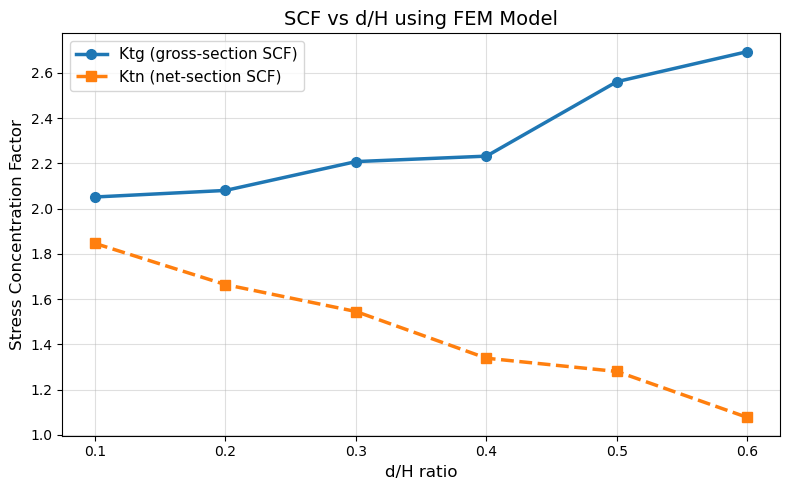

In [37]:
# ----------------------------------------
# Extract Ktg and Ktn from results list
# ----------------------------------------
ratios = [res["ratio"] for res in results]
Ktg_list = [res["Ktg"] for res in results]
Ktn_list = [res["Ktn"] for res in results]

# ----------------------------------------
# Plot Ktg and Ktn vs d/H
# ----------------------------------------
plt.figure(figsize=(8,5))

plt.plot(ratios, Ktg_list, 'o-', linewidth=2.5, markersize=7,
         label="Ktg (gross-section SCF)")

plt.plot(ratios, Ktn_list, 's--', linewidth=2.5, markersize=7,
         label="Ktn (net-section SCF)")

# ----------------------------------------
# Axes labels, title, style
# ----------------------------------------
plt.xlabel("d/H ratio", fontsize=12)
plt.ylabel("Stress Concentration Factor", fontsize=12)
plt.title("SCF vs d/H using FEM Model", fontsize=14)

plt.grid(True, alpha=0.4)
plt.legend(fontsize=11)

# ----------------------------------------
# Save high-quality figure
# ----------------------------------------
plt.tight_layout()
plt.savefig("SCF_vs_ratio_updated.pdf", dpi=300)
plt.savefig("SCF_vs_ratio_updated.png", dpi=300)

plt.show()
